In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/VisionInspect")

print("Project exists:", PROJECT_ROOT.exists())

for folder in PROJECT_ROOT.iterdir():
    print("-", folder.name)

Project exists: True
- data
- models
- notebooks
- results
- src


In [ ]:
BOTTLE_ROOT = PROJECT_ROOT / "data" / "bottle"

print("Bottle folder exists:", BOTTLE_ROOT.exists())
print("Train folder exists:", (BOTTLE_ROOT / "train").exists())
print("Test folder exists:", (BOTTLE_ROOT / "test").exists())
print("Ground truth folder exists:", (BOTTLE_ROOT / "ground_truth").exists())

Bottle folder exists: True
Train folder exists: True
Test folder exists: True
Ground truth folder exists: True


In [ ]:
train_good = BOTTLE_ROOT / "train" / "good"

train_images = list(train_good.glob("*.png"))

print("Normal training images:", len(train_images))

Normal training images: 209


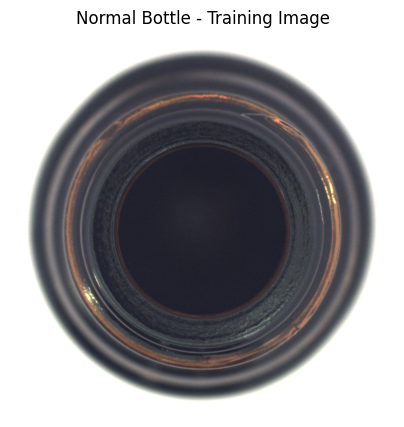

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = train_images[0]

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Normal Bottle - Training Image")
plt.axis("off")
plt.show()

In [ ]:
# Find one defective bottle image

broken_folder = BOTTLE_ROOT / "test" / "broken_large"

broken_images = sorted(
    broken_folder.glob("*.png")
)

print("Broken-large images:", len(broken_images))

defect_image_path = broken_images[0]

print("Selected image:", defect_image_path.name)

Broken-large images: 20
Selected image: 000.png


Broken-large images found: 20
Defective image: 000.png
Mask: 000_mask.png
Mask exists: True


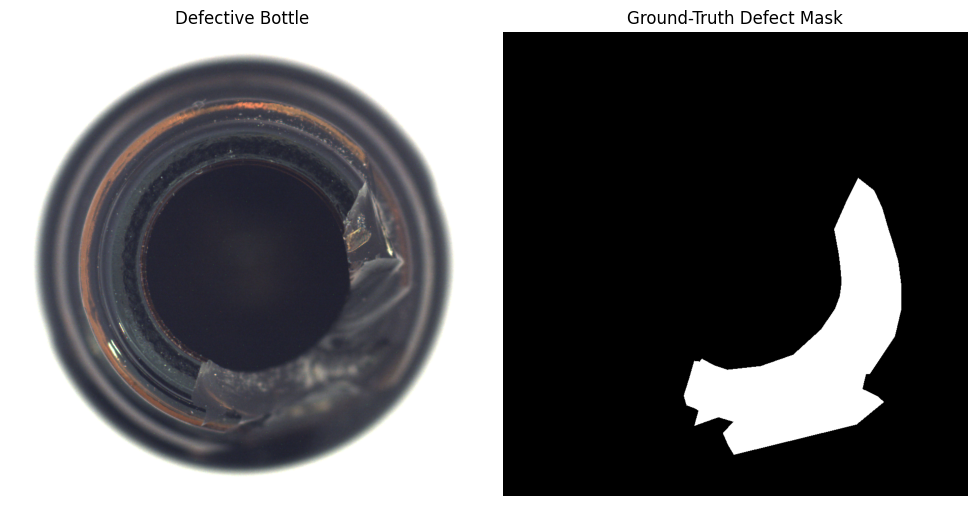

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Project paths
PROJECT_ROOT = Path("/content/drive/MyDrive/VisionInspect")
BOTTLE_ROOT = PROJECT_ROOT / "data" / "bottle"

# Select one defective image
broken_folder = BOTTLE_ROOT / "test" / "broken_large"

broken_images = sorted(
    broken_folder.glob("*.png")
)

print("Broken-large images found:", len(broken_images))

# Pick first defective image
defect_image_path = broken_images[0]

# Find its matching ground-truth mask
mask_path = (
    BOTTLE_ROOT
    / "ground_truth"
    / "broken_large"
    / f"{defect_image_path.stem}_mask.png"
)

print("Defective image:", defect_image_path.name)
print("Mask:", mask_path.name)
print("Mask exists:", mask_path.exists())

# Load images
defect_image = Image.open(
    defect_image_path
).convert("RGB")

defect_mask = Image.open(
    mask_path
).convert("L")

# Display them side by side
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)

axes[0].imshow(defect_image)
axes[0].set_title("Defective Bottle")
axes[0].axis("off")

axes[1].imshow(
    defect_mask,
    cmap="gray"
)
axes[1].set_title("Ground-Truth Defect Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Show all folders inside the test set

test_root = BOTTLE_ROOT / "test"

for folder in sorted(test_root.iterdir()):
    if folder.is_dir():
        images = list(folder.glob("*.png"))
        print(f"{folder.name}: {len(images)} images")

broken_large: 20 images
broken_small: 22 images
contamination: 21 images
good: 20 images


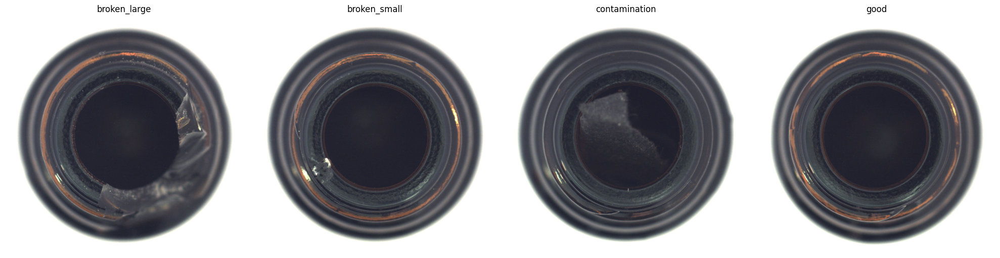

In [ ]:
# Show one example from every test category

from PIL import Image
import matplotlib.pyplot as plt

test_folders = [
    folder
    for folder in sorted(test_root.iterdir())
    if folder.is_dir()
]

fig, axes = plt.subplots(
    1,
    len(test_folders),
    figsize=(5 * len(test_folders), 5)
)

for ax, folder in zip(axes, test_folders):

    images = sorted(folder.glob("*.png"))

    image = Image.open(
        images[0]
    ).convert("RGB")

    ax.imshow(image)

    ax.set_title(
        folder.name
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
from torchvision import transforms

IMAGE_SIZE = 256

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transform created.")

Image transform created.


In [ ]:
# Test preprocessing on one normal image

sample_image = Image.open(
    train_images[0]
).convert("RGB")

sample_tensor = image_transform(
    sample_image
)

print("Tensor shape:", sample_tensor.shape)
print("Tensor type:", sample_tensor.dtype)
print("Minimum value:", sample_tensor.min().item())
print("Maximum value:", sample_tensor.max().item())

Tensor shape: torch.Size([3, 256, 256])
Tensor type: torch.float32
Minimum value: -1.621286153793335
Maximum value: 2.640000104904175


In [ ]:
from torch.utils.data import Dataset
from pathlib import Path
from PIL import Image
import torch


class MVTecBottleDataset(Dataset):

    def __init__(
        self,
        root,
        split="train",
        image_transform=None,
        image_size=256
    ):

        self.root = Path(root)
        self.split = split
        self.image_transform = image_transform
        self.image_size = image_size

        self.samples = []

        # Transform for defect masks
        self.mask_transform = transforms.Compose([
            transforms.Resize(
                (image_size, image_size),
                interpolation=transforms.InterpolationMode.NEAREST
            ),
            transforms.ToTensor()
        ])

        # ----------------------------
        # TRAINING DATA
        # ----------------------------
        if split == "train":

            good_folder = (
                self.root
                / "train"
                / "good"
            )

            for image_path in sorted(
                good_folder.glob("*.png")
            ):

                self.samples.append({
                    "image_path": image_path,
                    "defect_type": "good",
                    "mask_path": None
                })

        # ----------------------------
        # TEST DATA
        # ----------------------------
        elif split == "test":

            test_folder = (
                self.root
                / "test"
            )

            for defect_folder in sorted(
                test_folder.iterdir()
            ):

                if not defect_folder.is_dir():
                    continue

                defect_type = defect_folder.name

                for image_path in sorted(
                    defect_folder.glob("*.png")
                ):

                    mask_path = None

                    if defect_type != "good":

                        possible_mask = (
                            self.root
                            / "ground_truth"
                            / defect_type
                            / f"{image_path.stem}_mask.png"
                        )

                        if possible_mask.exists():
                            mask_path = possible_mask

                    self.samples.append({
                        "image_path": image_path,
                        "defect_type": defect_type,
                        "mask_path": mask_path
                    })

        else:

            raise ValueError(
                "split must be 'train' or 'test'"
            )


    def __len__(self):

        return len(self.samples)


    def __getitem__(self, index):

        sample = self.samples[index]

        # Load RGB image
        image = Image.open(
            sample["image_path"]
        ).convert("RGB")

        if self.image_transform is not None:
            image = self.image_transform(image)

        # 0 = normal
        # 1 = anomaly
        is_anomaly = (
            sample["defect_type"] != "good"
        )

        label = torch.tensor(
            int(is_anomaly),
            dtype=torch.long
        )

        # Create mask
        if sample["mask_path"] is None:

            mask = torch.zeros(
                1,
                self.image_size,
                self.image_size
            )

        else:

            mask_image = Image.open(
                sample["mask_path"]
            ).convert("L")

            mask = self.mask_transform(
                mask_image
            )

            mask = (
                mask > 0.5
            ).float()

        return {
            "image": image,
            "label": label,
            "mask": mask,
            "defect_type": sample["defect_type"],
            "path": str(sample["image_path"])
        }

In [ ]:
train_dataset = MVTecBottleDataset(
    root=BOTTLE_ROOT,
    split="train",
    image_transform=image_transform,
    image_size=IMAGE_SIZE
)

test_dataset = MVTecBottleDataset(
    root=BOTTLE_ROOT,
    split="test",
    image_transform=image_transform,
    image_size=IMAGE_SIZE
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

Training samples: 209
Test samples: 83


In [ ]:
sample = train_dataset[0]

print("Image shape:", sample["image"].shape)
print("Label:", sample["label"])
print("Mask shape:", sample["mask"].shape)
print("Defect type:", sample["defect_type"])
print("Path:", sample["path"])

Image shape: torch.Size([3, 256, 256])
Label: tensor(0)
Mask shape: torch.Size([1, 256, 256])
Defect type: good
Path: /content/drive/MyDrive/VisionInspect/data/bottle/train/good/000.png


In [ ]:
for sample in test_dataset:

    if sample["label"].item() == 1:

        print("Image shape:", sample["image"].shape)
        print("Label:", sample["label"])
        print("Mask shape:", sample["mask"].shape)
        print("Defect type:", sample["defect_type"])
        print("Mask pixels:", sample["mask"].sum().item())

        break


Image shape: torch.Size([3, 256, 256])
Label: tensor(1)
Mask shape: torch.Size([1, 256, 256])
Defect type: broken_large
Mask pixels: 7131.0


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Train batches: 27
Test batches: 11


In [ ]:
batch = next(iter(train_loader))

print("Images shape:", batch["image"].shape)
print("Labels shape:", batch["label"].shape)
print("Masks shape:", batch["mask"].shape)
print("Defect types:", batch["defect_type"][:5])

Images shape: torch.Size([8, 3, 256, 256])
Labels shape: torch.Size([8])
Masks shape: torch.Size([8, 1, 256, 256])
Defect types: ['good', 'good', 'good', 'good', 'good']


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

images = batch["image"].to(device)

print("Device:", device)
print("Batch device:", images.device)

Device: cuda
Batch device: cuda:0


In [ ]:
import torch
import torch.nn as nn


class ConvAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # -----------------------
        # ENCODER
        # -----------------------
        self.encoder = nn.Sequential(

            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=128,
                out_channels=256,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU()
        )

        # -----------------------
        # DECODER
        # -----------------------
        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                in_channels=256,
                out_channels=128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                in_channels=128,
                out_channels=64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                in_channels=64,
                out_channels=32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                in_channels=32,
                out_channels=3,
                kernel_size=4,
                stride=2,
                padding=1
            )
        )


    def forward(self, x):

        encoded = self.encoder(x)

        reconstructed = self.decoder(
            encoded
        )

        return reconstructed

In [ ]:
autoencoder = ConvAutoencoder().to(device)

print(autoencoder)

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): ReLU()
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  )
)


In [ ]:
total_parameters = sum(
    p.numel()
    for p in autoencoder.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    f"{total_parameters:,}"
)

Trainable parameters: 1,380,035


In [ ]:
batch = next(iter(train_loader))

images = batch["image"].to(device)

with torch.no_grad():

    reconstructed = autoencoder(
        images
    )

print(
    "Input shape:",
    images.shape
)

print(
    "Reconstruction shape:",
    reconstructed.shape
)

Input shape: torch.Size([8, 3, 256, 256])
Reconstruction shape: torch.Size([8, 3, 256, 256])


In [ ]:
from torch.utils.data import random_split, DataLoader
import torch

SEED = 42
BATCH_SIZE = 8

# 90% training, 10% validation
val_size = max(1, int(len(train_dataset) * 0.10))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))

Training images: 189
Validation images: 20


In [ ]:
import torch.nn as nn
import torch.optim as optim

# Re-create model so we start fresh
autoencoder = ConvAutoencoder().to(device)

criterion = nn.MSELoss()

optimizer = optim.Adam(
    autoencoder.parameters(),
    lr=1e-3
)

print("Model ready for training.")

Model ready for training.


In [ ]:
from pathlib import Path

MODEL_ROOT = PROJECT_ROOT / "models"
MODEL_ROOT.mkdir(parents=True, exist_ok=True)

AUTOENCODER_PATH = MODEL_ROOT / "autoencoder_bottle_best.pt"

print("Model will be saved to:")
print(AUTOENCODER_PATH)

Model will be saved to:
/content/drive/MyDrive/VisionInspect/models/autoencoder_bottle_best.pt


In [ ]:
from tqdm.auto import tqdm

EPOCHS = 20

train_losses = []
val_losses = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    # ==========================
    # TRAINING
    # ==========================
    autoencoder.train()

    running_train_loss = 0.0

    for batch in train_loader:

        images = batch["image"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        reconstructed = autoencoder(images)

        # Reconstruction error
        loss = criterion(
            reconstructed,
            images
        )

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_train_loss += (
            loss.item() * images.size(0)
        )

    train_loss = (
        running_train_loss
        / len(train_loader.dataset)
    )

    # ==========================
    # VALIDATION
    # ==========================
    autoencoder.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for batch in val_loader:

            images = batch["image"].to(device)

            reconstructed = autoencoder(images)

            loss = criterion(
                reconstructed,
                images
            )

            running_val_loss += (
                loss.item() * images.size(0)
            )

    val_loss = (
        running_val_loss
        / len(val_loader.dataset)
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

    # Save best model only
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "model_state_dict":
                    autoencoder.state_dict(),

                "epoch":
                    epoch + 1,

                "val_loss":
                    val_loss
            },
            AUTOENCODER_PATH
        )

        print("  ✓ Best model saved")

Epoch 01/20 | Train Loss: 1.390014 | Val Loss: 0.694572
  ✓ Best model saved
Epoch 02/20 | Train Loss: 0.305584 | Val Loss: 0.143531
  ✓ Best model saved
Epoch 03/20 | Train Loss: 0.106898 | Val Loss: 0.081775
  ✓ Best model saved
Epoch 04/20 | Train Loss: 0.071457 | Val Loss: 0.061116
  ✓ Best model saved
Epoch 05/20 | Train Loss: 0.056507 | Val Loss: 0.051216
  ✓ Best model saved
Epoch 06/20 | Train Loss: 0.049437 | Val Loss: 0.046442
  ✓ Best model saved
Epoch 07/20 | Train Loss: 0.045670 | Val Loss: 0.043119
  ✓ Best model saved
Epoch 08/20 | Train Loss: 0.042531 | Val Loss: 0.041594
  ✓ Best model saved
Epoch 09/20 | Train Loss: 0.040033 | Val Loss: 0.038068
  ✓ Best model saved
Epoch 10/20 | Train Loss: 0.039835 | Val Loss: 0.046513
Epoch 11/20 | Train Loss: 0.038342 | Val Loss: 0.035039
  ✓ Best model saved
Epoch 12/20 | Train Loss: 0.034567 | Val Loss: 0.033266
  ✓ Best model saved
Epoch 13/20 | Train Loss: 0.034797 | Val Loss: 0.036682
Epoch 14/20 | Train Loss: 0.032876 | Val 

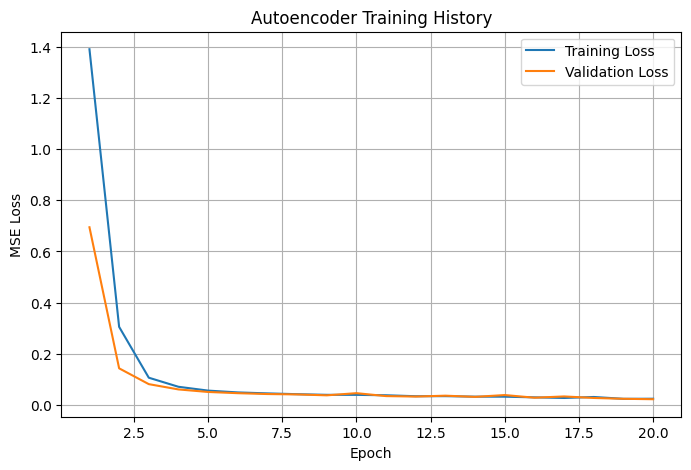

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training History")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print(
    "Model saved:",
    AUTOENCODER_PATH.exists()
)

print(
    "Best validation loss:",
    best_val_loss
)

Model saved: True
Best validation loss: 0.022856907173991203


In [ ]:
checkpoint = torch.load(
    AUTOENCODER_PATH,
    map_location=device
)

autoencoder.load_state_dict(
    checkpoint["model_state_dict"]
)

autoencoder.eval()

print(
    "Loaded model from epoch:",
    checkpoint["epoch"]
)

print(
    "Validation loss:",
    checkpoint["val_loss"]
)

Loaded model from epoch: 20
Validation loss: 0.022856907173991203


In [ ]:
def denormalize_image(tensor):

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    tensor = tensor.cpu()

    image = (
        tensor * std + mean
    )

    return image.clamp(0, 1)

In [ ]:
normal_sample = train_dataset[0]

normal_image = (
    normal_sample["image"]
    .unsqueeze(0)
    .to(device)
)

with torch.no_grad():

    normal_reconstruction = autoencoder(
        normal_image
    )

print(
    "Normal input:",
    normal_image.shape
)

print(
    "Normal reconstruction:",
    normal_reconstruction.shape
)

Normal input: torch.Size([1, 3, 256, 256])
Normal reconstruction: torch.Size([1, 3, 256, 256])


In [ ]:
defective_sample = None

for sample in test_dataset:

    if sample["label"].item() == 1:

        defective_sample = sample
        break


defective_image = (
    defective_sample["image"]
    .unsqueeze(0)
    .to(device)
)

with torch.no_grad():

    defective_reconstruction = autoencoder(
        defective_image
    )

print(
    "Defect type:",
    defective_sample["defect_type"]
)

Defect type: broken_large


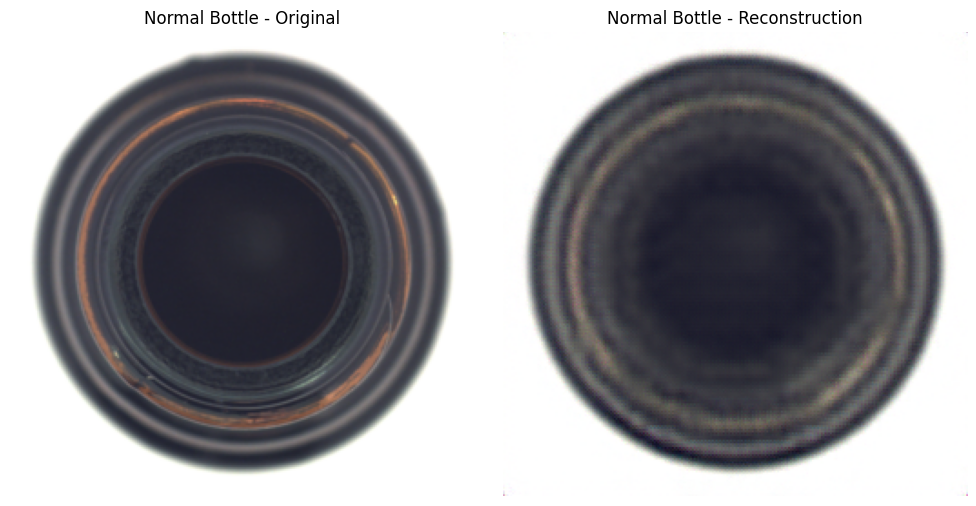

In [ ]:
normal_original_display = denormalize_image(
    normal_image[0]
)

normal_reconstructed_display = denormalize_image(
    normal_reconstruction[0]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)

axes[0].imshow(
    normal_original_display.permute(1, 2, 0)
)

axes[0].set_title(
    "Normal Bottle - Original"
)

axes[0].axis("off")


axes[1].imshow(
    normal_reconstructed_display.permute(1, 2, 0)
)

axes[1].set_title(
    "Normal Bottle - Reconstruction"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

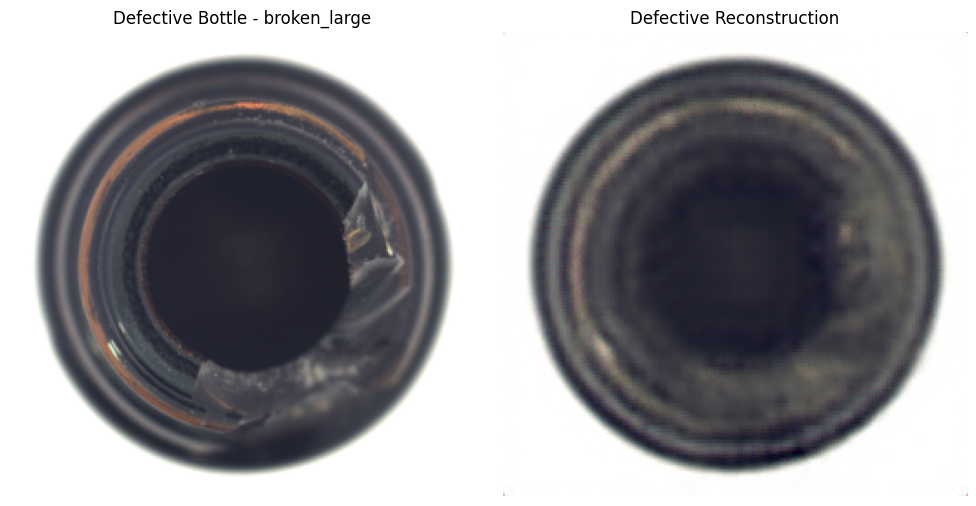

In [ ]:
defective_original_display = denormalize_image(
    defective_image[0]
)

defective_reconstructed_display = denormalize_image(
    defective_reconstruction[0]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)

axes[0].imshow(
    defective_original_display.permute(1, 2, 0)
)

axes[0].set_title(
    f"Defective Bottle - {defective_sample['defect_type']}"
)

axes[0].axis("off")


axes[1].imshow(
    defective_reconstructed_display.permute(1, 2, 0)
)

axes[1].set_title(
    "Defective Reconstruction"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch.nn.functional as F


def reconstruction_anomaly_map(
    original,
    reconstructed
):

    # Pixel-wise squared reconstruction error
    error_map = torch.mean(
        (original - reconstructed) ** 2,
        dim=1,
        keepdim=True
    )

    # Slight smoothing for cleaner visualization
    error_map = F.avg_pool2d(
        error_map,
        kernel_size=5,
        stride=1,
        padding=2
    )

    return error_map

In [ ]:
with torch.no_grad():

    normal_error_map = reconstruction_anomaly_map(
        normal_image,
        normal_reconstruction
    )

print(
    "Normal anomaly map shape:",
    normal_error_map.shape
)

Normal anomaly map shape: torch.Size([1, 1, 256, 256])


In [ ]:
with torch.no_grad():

    defective_error_map = reconstruction_anomaly_map(
        defective_image,
        defective_reconstruction
    )

print(
    "Defective anomaly map shape:",
    defective_error_map.shape
)

Defective anomaly map shape: torch.Size([1, 1, 256, 256])


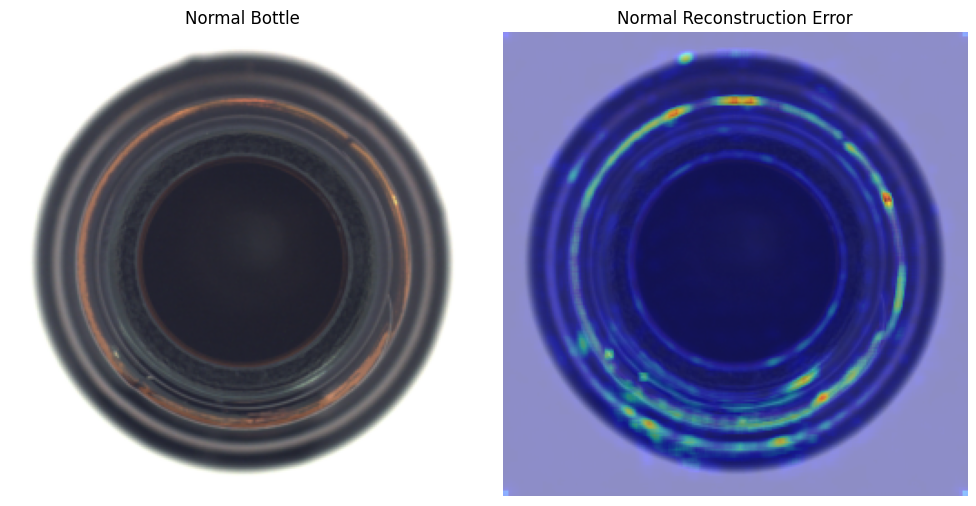

In [ ]:
normal_map = (
    normal_error_map[0, 0]
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)

axes[0].imshow(
    normal_original_display.permute(1, 2, 0)
)

axes[0].set_title(
    "Normal Bottle"
)

axes[0].axis("off")


axes[1].imshow(
    normal_original_display.permute(1, 2, 0)
)

axes[1].imshow(
    normal_map,
    cmap="jet",
    alpha=0.45
)

axes[1].set_title(
    "Normal Reconstruction Error"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

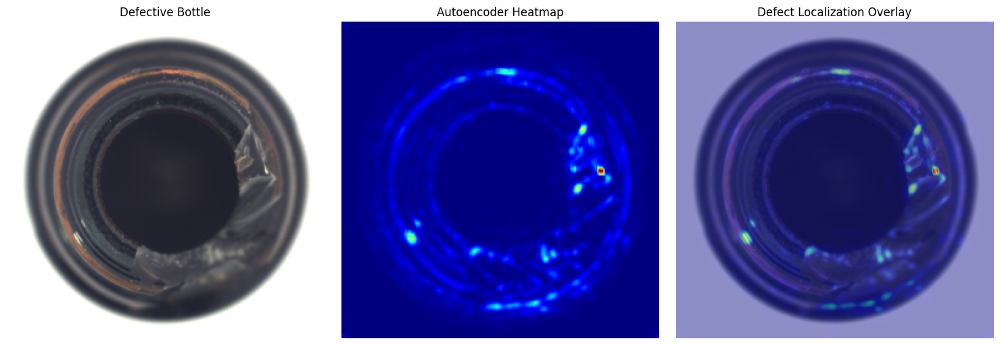

In [ ]:
defective_map = (
    defective_error_map[0, 0]
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

# Original defective image
axes[0].imshow(
    defective_original_display.permute(1, 2, 0)
)

axes[0].set_title(
    "Defective Bottle"
)

axes[0].axis("off")


# Predicted reconstruction-error heatmap
axes[1].imshow(
    defective_map,
    cmap="jet"
)

axes[1].set_title(
    "Autoencoder Heatmap"
)

axes[1].axis("off")


# Overlay
axes[2].imshow(
    defective_original_display.permute(1, 2, 0)
)

axes[2].imshow(
    defective_map,
    cmap="jet",
    alpha=0.45
)

axes[2].set_title(
    "Defect Localization Overlay"
)

axes[2].axis("off")

plt.tight_layout()
plt.show()

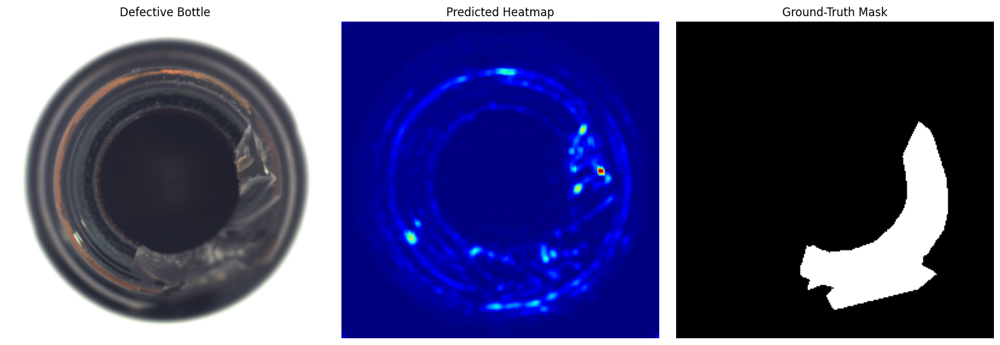

In [ ]:
ground_truth_mask = (
    defective_sample["mask"][0]
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

axes[0].imshow(
    defective_original_display.permute(1, 2, 0)
)
axes[0].set_title("Defective Bottle")
axes[0].axis("off")

axes[1].imshow(
    defective_map,
    cmap="jet"
)
axes[1].set_title("Predicted Heatmap")
axes[1].axis("off")

axes[2].imshow(
    ground_truth_mask,
    cmap="gray"
)
axes[2].set_title("Ground-Truth Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def get_image_anomaly_score(error_map, top_percent=0.01):

    # Flatten each heatmap
    flattened = error_map.flatten(start_dim=1)

    # Number of highest-error pixels to use
    k = max(
        1,
        int(flattened.shape[1] * top_percent)
    )

    # Get highest anomaly values
    top_values = torch.topk(
        flattened,
        k=k,
        dim=1
    ).values

    # Average them
    scores = top_values.mean(dim=1)

    return scores

In [ ]:
all_labels = []
all_scores = []
all_defect_types = []

autoencoder.eval()

with torch.no_grad():

    for batch in test_loader:

        images = batch["image"].to(device)

        reconstructed = autoencoder(images)

        error_maps = reconstruction_anomaly_map(
            images,
            reconstructed
        )

        scores = get_image_anomaly_score(
            error_maps
        )

        all_scores.extend(
            scores.cpu().numpy().tolist()
        )

        all_labels.extend(
            batch["label"].cpu().numpy().tolist()
        )

        all_defect_types.extend(
            batch["defect_type"]
        )

print("Images evaluated:", len(all_scores))
print("Labels:", len(all_labels))

Images evaluated: 83
Labels: 83


In [ ]:
from sklearn.metrics import roc_auc_score

image_auroc = roc_auc_score(
    all_labels,
    all_scores
)

print(
    f"Autoencoder Image AUROC: {image_auroc:.4f}"
)

Autoencoder Image AUROC: 0.8611


In [ ]:
import pandas as pd

results_df = pd.DataFrame({
    "label": all_labels,
    "score": all_scores,
    "defect_type": all_defect_types
})

results_df.groupby(
    "defect_type"
)["score"].agg(
    ["mean", "std", "min", "max", "count"]
)

,mean,std,min,max,count
defect_type,,,,,
broken_large,0.637554,0.228620,0.355919,1.073062,20
broken_small,0.746264,0.294808,0.334029,1.457504,22
contamination,0.510067,0.429477,0.240897,1.951307,21
good,0.331811,0.055613,0.219376,0.486273,20


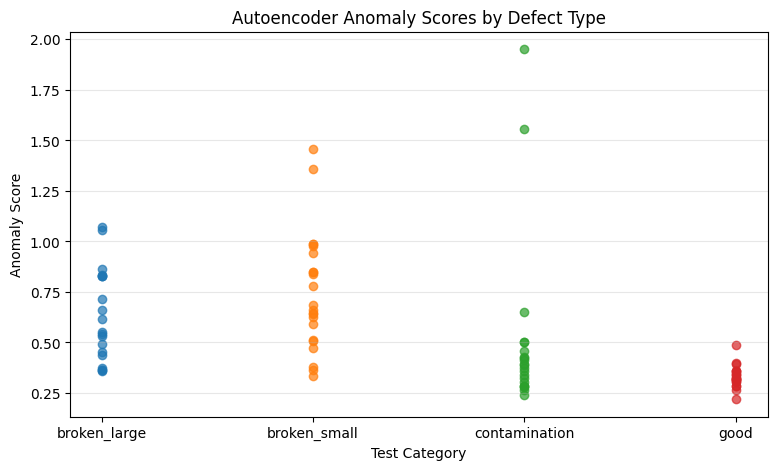

In [ ]:
plt.figure(figsize=(9, 5))

for defect_type in results_df["defect_type"].unique():

    subset = results_df[
        results_df["defect_type"] == defect_type
    ]

    plt.scatter(
        [defect_type] * len(subset),
        subset["score"],
        alpha=0.7
    )

plt.ylabel("Anomaly Score")
plt.xlabel("Test Category")
plt.title("Autoencoder Anomaly Scores by Defect Type")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score

pixel_labels = []
pixel_scores = []

autoencoder.eval()

with torch.no_grad():

    for batch in test_loader:

        images = batch["image"].to(device)

        masks = batch["mask"]

        reconstructed = autoencoder(images)

        error_maps = reconstruction_anomaly_map(
            images,
            reconstructed
        )

        # Move to CPU
        error_maps = error_maps.cpu().numpy()
        masks = masks.cpu().numpy()

        # Flatten every pixel
        pixel_scores.append(
            error_maps.reshape(-1)
        )

        pixel_labels.append(
            masks.reshape(-1)
        )

pixel_scores = np.concatenate(pixel_scores)

pixel_labels = np.concatenate(pixel_labels)

print("Total pixels evaluated:", len(pixel_scores))
print("Defective pixels:", int(pixel_labels.sum()))

Total pixels evaluated: 5439488
Defective pixels: 314384


In [ ]:
pixel_auroc = roc_auc_score(
    pixel_labels,
    pixel_scores
)

print(
    f"Autoencoder Pixel AUROC: {pixel_auroc:.4f}"
)

Autoencoder Pixel AUROC: 0.7184


In [ ]:
baseline_results = {
    "model": "Convolutional Autoencoder",
    "category": "bottle",
    "image_auroc": image_auroc,
    "pixel_auroc": pixel_auroc
}

baseline_results

{'model': 'Convolutional Autoencoder',
 'category': 'bottle',
 'image_auroc': np.float64(0.861111111111111),
 'pixel_auroc': np.float64(0.7183539824466114)}

In [ ]:
import pandas as pd

RESULT_ROOT = PROJECT_ROOT / "results"

baseline_df = pd.DataFrame(
    [baseline_results]
)

baseline_df.to_csv(
    RESULT_ROOT / "autoencoder_bottle_metrics.csv",
    index=False
)

print("Results saved.")

Results saved.


In [ ]:
validation_scores = []

autoencoder.eval()

with torch.no_grad():

    for batch in val_loader:

        images = batch["image"].to(device)

        reconstructed = autoencoder(images)

        error_maps = reconstruction_anomaly_map(
            images,
            reconstructed
        )

        scores = get_image_anomaly_score(
            error_maps
        )

        validation_scores.extend(
            scores.cpu().numpy().tolist()
        )

print(
    "Validation images scored:",
    len(validation_scores)
)

print(
    "Minimum validation score:",
    min(validation_scores)
)

print(
    "Maximum validation score:",
    max(validation_scores)
)

Validation images scored: 20
Minimum validation score: 0.19405461847782135
Maximum validation score: 0.509349524974823


In [ ]:
import numpy as np

threshold = np.percentile(
    validation_scores,
    95
)

print(
    f"Anomaly threshold: {threshold:.4f}"
)

Anomaly threshold: 0.3581


In [ ]:
all_scores
all_labels

[1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [ ]:
test_predictions = [
    1 if score >= threshold else 0
    for score in all_scores
]

print(
    "Test predictions created:",
    len(test_predictions)
)

Test predictions created: 83


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(
    all_labels,
    test_predictions
)

precision = precision_score(
    all_labels,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    all_labels,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    test_predictions,
    zero_division=0
)

print(
    f"Accuracy:  {accuracy:.4f}"
)

print(
    f"Precision: {precision:.4f}"
)

print(
    f"Recall:    {recall:.4f}"
)

print(
    f"F1 Score:  {f1:.4f}"
)

Accuracy:  0.8193
Precision: 0.9138
Recall:    0.8413
F1 Score:  0.8760


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    test_predictions
)

print(cm)

[[15  5]
 [10 53]]


In [ ]:
tn, fp, fn, tp = cm.ravel()

print("True Normal:", tn)
print("False Alarm:", fp)
print("Missed Defect:", fn)
print("Detected Defect:", tp)

True Normal: 15
False Alarm: 5
Missed Defect: 10
Detected Defect: 53


In [ ]:
complete_autoencoder_results = {
    "model": "Convolutional Autoencoder",
    "category": "bottle",
    "image_auroc": float(image_auroc),
    "pixel_auroc": float(pixel_auroc),
    "threshold": float(threshold),
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1)
}

complete_autoencoder_results

{'model': 'Convolutional Autoencoder',
 'category': 'bottle',
 'image_auroc': 0.861111111111111,
 'pixel_auroc': 0.7183539824466114,
 'threshold': 0.3580708384513856,
 'accuracy': 0.8192771084337349,
 'precision': 0.9137931034482759,
 'recall': 0.8412698412698413,
 'f1': 0.8760330578512396}

In [ ]:
autoencoder_results_df = pd.DataFrame(
    [complete_autoencoder_results]
)

autoencoder_results_df.to_csv(
    RESULT_ROOT / "autoencoder_bottle_metrics.csv",
    index=False
)

print("Complete Autoencoder results saved.")

Complete Autoencoder results saved.


In [ ]:
import torch
import torchvision

from torchvision.models import (
    wide_resnet50_2,
    Wide_ResNet50_2_Weights
)

from torchvision.models.feature_extraction import (
    create_feature_extractor
)

In [ ]:
weights = Wide_ResNet50_2_Weights.DEFAULT

backbone = wide_resnet50_2(
    weights=weights
)

print("WideResNet50-2 loaded.")

Downloading: "https://download.pytorch.org/models/wide_resnet50_2-9ba9bcbe.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-9ba9bcbe.pth


100%|██████████| 263M/263M [00:03<00:00, 88.8MB/s]


WideResNet50-2 loaded.


In [ ]:
backbone.eval()

for parameter in backbone.parameters():
    parameter.requires_grad = False

print("Backbone frozen.")

Backbone frozen.


In [ ]:
feature_extractor = create_feature_extractor(
    backbone,
    return_nodes={
        "layer2": "layer2",
        "layer3": "layer3"
    }
)

feature_extractor = feature_extractor.to(device)

feature_extractor.eval()

print("Feature extractor ready.")

Feature extractor ready.


In [ ]:
batch = next(iter(train_loader))

images = batch["image"].to(device)

print(
    "Input batch shape:",
    images.shape
)

Input batch shape: torch.Size([8, 3, 256, 256])


In [ ]:
with torch.no_grad():

    features = feature_extractor(
        images
    )

In [ ]:
print(
    "Layer 2 shape:",
    features["layer2"].shape
)

print(
    "Layer 3 shape:",
    features["layer3"].shape
)

Layer 2 shape: torch.Size([8, 512, 32, 32])
Layer 3 shape: torch.Size([8, 1024, 16, 16])


In [ ]:
trainable_parameters = sum(
    p.numel()
    for p in feature_extractor.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    trainable_parameters
)

Trainable parameters: 0


In [ ]:
import torch.nn.functional as F


def extract_patch_embeddings(images):

    with torch.no_grad():

        features = feature_extractor(images)

        layer2 = features["layer2"]
        layer3 = features["layer3"]

        # Resize layer3 so it matches layer2 spatial size
        layer3_resized = F.interpolate(
            layer3,
            size=layer2.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Combine layer2 + layer3 channels
        combined = torch.cat(
            [layer2, layer3_resized],
            dim=1
        )

        batch_size, channels, height, width = combined.shape

        # Convert feature map into local patch vectors
        patches = (
            combined
            .permute(0, 2, 3, 1)
            .reshape(
                batch_size,
                height * width,
                channels
            )
        )

        # Normalize each patch vector
        patches = F.normalize(
            patches,
            p=2,
            dim=2
        )

    return patches, height, width

In [ ]:
batch = next(iter(train_loader))

images = batch["image"].to(device)

patch_embeddings, patch_h, patch_w = extract_patch_embeddings(
    images
)

print(
    "Patch embedding shape:",
    patch_embeddings.shape
)

print(
    "Patch grid:",
    patch_h,
    "x",
    patch_w
)

Patch embedding shape: torch.Size([8, 1024, 1536])
Patch grid: 32 x 32


In [ ]:
first_image_patches = patch_embeddings[0]

print(
    "Number of patches in first image:",
    first_image_patches.shape[0]
)

print(
    "Features per patch:",
    first_image_patches.shape[1]
)

print(
    "\nFirst 10 values of first patch:"
)

print(
    first_image_patches[0][:10]
)

Number of patches in first image: 1024
Features per patch: 1536

First 10 values of first patch:
tensor([0.0000e+00, 2.1173e-05, 2.8837e-02, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 4.6248e-02, 0.0000e+00], device='cuda:0')


In [ ]:
patch_norm = torch.norm(
    patch_embeddings[0, 0],
    p=2
)

print(
    "First patch vector norm:",
    patch_norm.item()
)

First patch vector norm: 0.9999999403953552


In [ ]:
import math
import torch
import torch.nn.functional as F

EMBEDDING_DIM = 128
SEED = 42

torch.manual_seed(SEED)

# Original patch dimension from Step 17
INPUT_DIM = patch_embeddings.shape[-1]

projection_matrix = torch.randn(
    INPUT_DIM,
    EMBEDDING_DIM,
    device=device
)

projection_matrix = (
    projection_matrix
    / math.sqrt(EMBEDDING_DIM)
)

print("Original dimension:", INPUT_DIM)
print("Projected dimension:", EMBEDDING_DIM)
print("Projection shape:", projection_matrix.shape)

Original dimension: 1536
Projected dimension: 128
Projection shape: torch.Size([1536, 128])


In [ ]:
def project_patch_embeddings(patches):

    # patches:
    # [batch, patches, 1536]

    projected = torch.matmul(
        patches,
        projection_matrix
    )

    projected = F.normalize(
        projected,
        p=2,
        dim=-1
    )

    return projected

In [ ]:
projected_test = project_patch_embeddings(
    patch_embeddings
)

print(
    "Before projection:",
    patch_embeddings.shape
)

print(
    "After projection:",
    projected_test.shape
)

Before projection: torch.Size([8, 1024, 1536])
After projection: torch.Size([8, 1024, 128])


In [ ]:
normal_feature_batches = []

feature_extractor.eval()

with torch.no_grad():

    for batch_number, batch in enumerate(train_loader):

        images = batch["image"].to(device)

        # Extract multi-scale patch embeddings
        patches, _, _ = extract_patch_embeddings(
            images
        )

        # 1536 -> 128
        patches = project_patch_embeddings(
            patches
        )

        # [B, 1024, 128]
        # becomes
        # [B * 1024, 128]

        patches = patches.reshape(
            -1,
            EMBEDDING_DIM
        )

        # Move immediately to CPU
        # so GPU memory does not keep growing
        normal_feature_batches.append(
            patches.cpu()
        )

        if (batch_number + 1) % 5 == 0:

            print(
                f"Processed {batch_number + 1} batches"
            )

Processed 5 batches
Processed 10 batches
Processed 15 batches
Processed 20 batches


In [ ]:
full_memory_candidates = torch.cat(
    normal_feature_batches,
    dim=0
)

print(
    "All normal patch features:",
    full_memory_candidates.shape
)

All normal patch features: torch.Size([193536, 128])


In [ ]:
MAX_CANDIDATES = 10000

generator = torch.Generator()
generator.manual_seed(SEED)

if len(full_memory_candidates) > MAX_CANDIDATES:

    random_indices = torch.randperm(
        len(full_memory_candidates),
        generator=generator
    )[:MAX_CANDIDATES]

    candidate_features = (
        full_memory_candidates[
            random_indices
        ]
    )

else:

    candidate_features = (
        full_memory_candidates
    )

print(
    "Candidate features:",
    candidate_features.shape
)

Candidate features: torch.Size([10000, 128])


In [ ]:
def greedy_k_center(
    features,
    coreset_size,
    device
):

    features = features.to(device)

    number_of_features = len(features)

    # Start with one random feature
    generator = torch.Generator(
        device=device
    )

    generator.manual_seed(SEED)

    first_index = torch.randint(
        0,
        number_of_features,
        (1,),
        generator=generator,
        device=device
    ).item()

    selected_indices = [
        first_index
    ]

    first_center = features[
        first_index
    ]

    # Distance from every feature
    # to the first selected center
    min_distances = torch.norm(
        features - first_center,
        dim=1
    )

    for step in range(
        1,
        coreset_size
    ):

        # Choose the point farthest
        # from all currently selected points
        next_index = torch.argmax(
            min_distances
        ).item()

        selected_indices.append(
            next_index
        )

        new_center = features[
            next_index
        ]

        new_distances = torch.norm(
            features - new_center,
            dim=1
        )

        # Keep distance to nearest
        # selected center
        min_distances = torch.minimum(
            min_distances,
            new_distances
        )

        if (
            (step + 1) % 100 == 0
            or step + 1 == coreset_size
        ):

            print(
                f"Selected "
                f"{step + 1}/"
                f"{coreset_size}"
            )

    return torch.tensor(
        selected_indices,
        dtype=torch.long
    )

In [ ]:
CORESET_SIZE = 500

selected_indices = greedy_k_center(
    candidate_features,
    coreset_size=CORESET_SIZE,
    device=device
)

Selected 100/500
Selected 200/500
Selected 300/500
Selected 400/500
Selected 500/500


In [ ]:
memory_bank = candidate_features[
    selected_indices
].clone()

print(
    "Final memory bank:",
    memory_bank.shape
)

Final memory bank: torch.Size([500, 128])


In [ ]:
PATCHCORE_MEMORY_PATH = (
    MODEL_ROOT
    / "patchcore_bottle_memory.pt"
)

torch.save(
    {
        "memory_bank":
            memory_bank,

        "projection_matrix":
            projection_matrix.cpu(),

        "embedding_dim":
            EMBEDDING_DIM,

        "coreset_size":
            CORESET_SIZE,

        "max_candidates":
            MAX_CANDIDATES,

        "seed":
            SEED
    },
    PATCHCORE_MEMORY_PATH
)

print(
    "Saved:",
    PATCHCORE_MEMORY_PATH
)

print(
    "File exists:",
    PATCHCORE_MEMORY_PATH.exists()
)

Saved: /content/drive/MyDrive/VisionInspect/models/patchcore_bottle_memory.pt
File exists: True


In [ ]:
checkpoint = torch.load(
    PATCHCORE_MEMORY_PATH,
    map_location="cpu"
)

memory_bank = checkpoint[
    "memory_bank"
]

projection_matrix = checkpoint[
    "projection_matrix"
].to(device)

print(
    "Memory bank:",
    memory_bank.shape
)

print(
    "Projection matrix:",
    projection_matrix.shape
)

Memory bank: torch.Size([500, 128])
Projection matrix: torch.Size([1536, 128])


In [ ]:
def patchcore_score(images):

    # -------------------------
    # 1. Extract CNN patches
    # -------------------------
    patches, patch_h, patch_w = (
        extract_patch_embeddings(images)
    )

    # -------------------------
    # 2. Project 1536 -> 128
    # -------------------------
    patches = project_patch_embeddings(
        patches
    )

    batch_size = patches.shape[0]

    # [B, 1024, 128]
    # ->
    # [B*1024, 128]

    flat_patches = patches.reshape(
        -1,
        EMBEDDING_DIM
    )

    # Move normal memory to GPU
    normal_memory = memory_bank.to(device)

    # -------------------------
    # 3. Compare every test patch
    #    with normal memory patches
    # -------------------------
    distances = torch.cdist(
        flat_patches,
        normal_memory
    )

    # Nearest normal patch
    nearest_distances = (
        distances
        .min(dim=1)
        .values
    )

    # -------------------------
    # 4. Restore spatial layout
    # -------------------------
    anomaly_maps = nearest_distances.reshape(
        batch_size,
        patch_h,
        patch_w
    )

    # -------------------------
    # 5. Image-level score
    # -------------------------

    flat_maps = anomaly_maps.flatten(
        start_dim=1
    )

    # Average top 1% most
    # anomalous patches
    k = max(
        1,
        int(flat_maps.shape[1] * 0.01)
    )

    image_scores = torch.topk(
        flat_maps,
        k=k,
        dim=1
    ).values.mean(dim=1)

    return (
        image_scores.cpu(),
        anomaly_maps.cpu()
    )

In [ ]:
normal_batch = next(
    iter(train_loader)
)

normal_images = (
    normal_batch["image"]
    .to(device)
)

with torch.no_grad():

    normal_scores, normal_maps = (
        patchcore_score(
            normal_images
        )
    )

print(
    "Normal scores:"
)

print(
    normal_scores
)

print(
    "\nAnomaly map shape:",
    normal_maps.shape
)

Normal scores:
tensor([0.5850, 0.5533, 0.5752, 0.5681, 0.5492, 0.5941, 0.5670, 0.5604])

Anomaly map shape: torch.Size([8, 32, 32])


In [ ]:
defective_image_batch = (
    defective_sample["image"]
    .unsqueeze(0)
    .to(device)
)

with torch.no_grad():

    defect_score, defect_map = (
        patchcore_score(
            defective_image_batch
        )
    )

print(
    "Defect type:",
    defective_sample["defect_type"]
)

print(
    "PatchCore anomaly score:",
    defect_score.item()
)

print(
    "Anomaly map shape:",
    defect_map.shape
)

Defect type: broken_large
PatchCore anomaly score: 0.783694863319397
Anomaly map shape: torch.Size([1, 32, 32])


In [ ]:
print(
    "Normal score:",
    normal_scores[0].item()
)

print(
    "Defective score:",
    defect_score.item()
)

Normal score: 0.584976851940155
Defective score: 0.783694863319397


In [ ]:
import torch.nn.functional as F

def upscale_patchcore_map(
    anomaly_map,
    output_size=256
):

    # anomaly_map:
    # [B, 32, 32]

    anomaly_map = anomaly_map.unsqueeze(1)

    # [B, 1, 32, 32]
    # ->
    # [B, 1, 256, 256]

    anomaly_map = F.interpolate(
        anomaly_map,
        size=(output_size, output_size),
        mode="bilinear",
        align_corners=False
    )

    # Light smoothing
    anomaly_map = F.avg_pool2d(
        anomaly_map,
        kernel_size=5,
        stride=1,
        padding=2
    )

    return anomaly_map

In [ ]:
upscaled_defect_map = upscale_patchcore_map(
    defect_map,
    output_size=IMAGE_SIZE
)

print(
    "Original PatchCore map:",
    defect_map.shape
)

print(
    "Upscaled map:",
    upscaled_defect_map.shape
)

Original PatchCore map: torch.Size([1, 32, 32])
Upscaled map: torch.Size([1, 1, 256, 256])


In [ ]:
def normalize_heatmap(heatmap):

    heatmap = heatmap.clone()

    min_value = heatmap.min()
    max_value = heatmap.max()

    heatmap = (
        heatmap - min_value
    ) / (
        max_value - min_value + 1e-8
    )

    return heatmap

In [ ]:
normalized_defect_map = normalize_heatmap(
    upscaled_defect_map
)

print(
    "Min:",
    normalized_defect_map.min().item()
)

print(
    "Max:",
    normalized_defect_map.max().item()
)

Min: 0.0
Max: 1.0


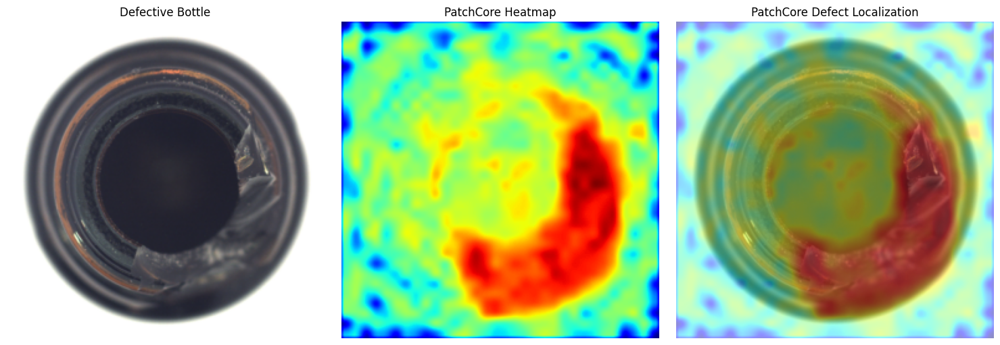

In [ ]:
patchcore_map_display = (
    normalized_defect_map[0, 0]
    .cpu()
    .numpy()
)

defective_display = denormalize_image(
    defective_sample["image"]
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

# Original
axes[0].imshow(
    defective_display.permute(1, 2, 0)
)

axes[0].set_title(
    "Defective Bottle"
)

axes[0].axis("off")


# PatchCore heatmap
axes[1].imshow(
    patchcore_map_display,
    cmap="jet"
)

axes[1].set_title(
    "PatchCore Heatmap"
)

axes[1].axis("off")


# Overlay
axes[2].imshow(
    defective_display.permute(1, 2, 0)
)

axes[2].imshow(
    patchcore_map_display,
    cmap="jet",
    alpha=0.45
)

axes[2].set_title(
    "PatchCore Defect Localization"
)

axes[2].axis("off")


plt.tight_layout()
plt.show()

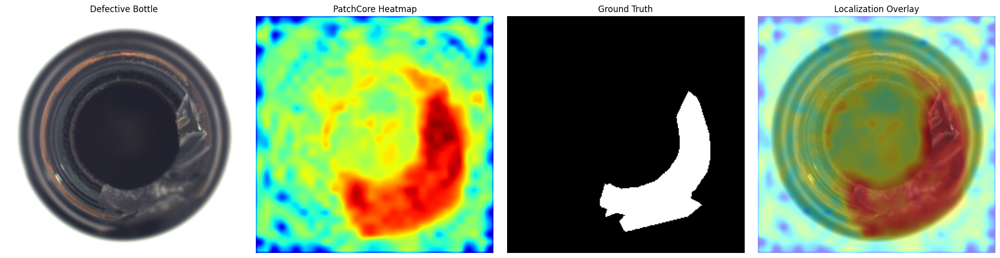

In [ ]:
ground_truth_mask = (
    defective_sample["mask"][0]
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

axes[0].imshow(
    defective_display.permute(1, 2, 0)
)
axes[0].set_title("Defective Bottle")
axes[0].axis("off")


axes[1].imshow(
    patchcore_map_display,
    cmap="jet"
)
axes[1].set_title("PatchCore Heatmap")
axes[1].axis("off")


axes[2].imshow(
    ground_truth_mask,
    cmap="gray"
)
axes[2].set_title("Ground Truth")
axes[2].axis("off")


axes[3].imshow(
    defective_display.permute(1, 2, 0)
)

axes[3].imshow(
    patchcore_map_display,
    cmap="jet",
    alpha=0.45
)

axes[3].set_title(
    "Localization Overlay"
)

axes[3].axis("off")


plt.tight_layout()
plt.show()

In [ ]:
RESULT_HEATMAP_ROOT = (
    PROJECT_ROOT
    / "results"
    / "heatmaps"
)

RESULT_HEATMAP_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

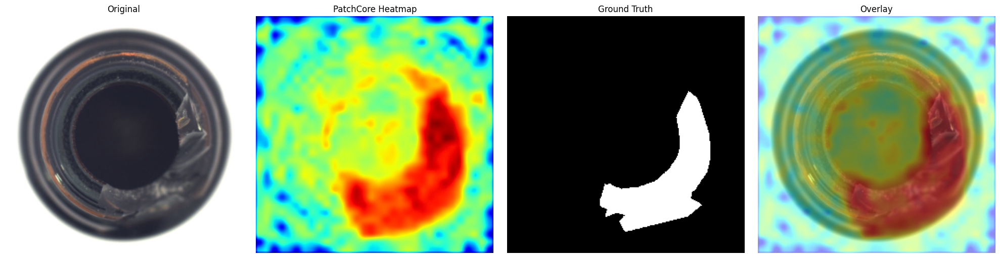

Saved: /content/drive/MyDrive/VisionInspect/results/heatmaps/patchcore_bottle_example.png


In [ ]:
fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

axes[0].imshow(
    defective_display.permute(1, 2, 0)
)
axes[0].set_title("Original")
axes[0].axis("off")


axes[1].imshow(
    patchcore_map_display,
    cmap="jet"
)
axes[1].set_title("PatchCore Heatmap")
axes[1].axis("off")


axes[2].imshow(
    ground_truth_mask,
    cmap="gray"
)
axes[2].set_title("Ground Truth")
axes[2].axis("off")


axes[3].imshow(
    defective_display.permute(1, 2, 0)
)

axes[3].imshow(
    patchcore_map_display,
    cmap="jet",
    alpha=0.45
)

axes[3].set_title("Overlay")
axes[3].axis("off")


plt.tight_layout()

save_path = (
    RESULT_HEATMAP_ROOT
    / "patchcore_bottle_example.png"
)

plt.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    save_path
)

In [ ]:
patchcore_labels = []
patchcore_scores = []

patchcore_pixel_labels = []
patchcore_pixel_scores = []

patchcore_defect_types = []

with torch.no_grad():

    for batch in test_loader:

        images = batch["image"].to(device)

        labels = batch["label"]
        masks = batch["mask"]

        # PatchCore scoring
        image_scores, anomaly_maps = patchcore_score(
            images
        )

        # Upscale 32x32 maps -> 256x256
        anomaly_maps = upscale_patchcore_map(
            anomaly_maps,
            output_size=IMAGE_SIZE
        )

        patchcore_scores.extend(
            image_scores.numpy().tolist()
        )

        patchcore_labels.extend(
            labels.numpy().tolist()
        )

        patchcore_defect_types.extend(
            batch["defect_type"]
        )

        patchcore_pixel_scores.append(
            anomaly_maps.numpy().reshape(-1)
        )

        patchcore_pixel_labels.append(
            masks.numpy().reshape(-1)
        )

In [ ]:
import numpy as np

patchcore_pixel_scores = np.concatenate(
    patchcore_pixel_scores
)

patchcore_pixel_labels = np.concatenate(
    patchcore_pixel_labels
)

print(
    "Images evaluated:",
    len(patchcore_scores)
)

print(
    "Pixels evaluated:",
    len(patchcore_pixel_scores)
)

Images evaluated: 83
Pixels evaluated: 5439488


In [ ]:
from sklearn.metrics import roc_auc_score

patchcore_image_auroc = roc_auc_score(
    patchcore_labels,
    patchcore_scores
)

print(
    f"PatchCore Image AUROC: "
    f"{patchcore_image_auroc:.4f}"
)

PatchCore Image AUROC: 1.0000


In [ ]:
patchcore_pixel_auroc = roc_auc_score(
    patchcore_pixel_labels,
    patchcore_pixel_scores
)

print(
    f"PatchCore Pixel AUROC: "
    f"{patchcore_pixel_auroc:.4f}"
)

PatchCore Pixel AUROC: 0.9819


In [ ]:
import pandas as pd

patchcore_results_df = pd.DataFrame({
    "label": patchcore_labels,
    "score": patchcore_scores,
    "defect_type": patchcore_defect_types
})

patchcore_results_df.groupby(
    "defect_type"
)["score"].agg(
    ["mean", "std", "min", "max", "count"]
)

,mean,std,min,max,count
defect_type,,,,,
broken_large,0.798603,0.021807,0.748210,0.844612,20
broken_small,0.787966,0.035298,0.694557,0.848575,22
contamination,0.766800,0.069775,0.662235,0.884728,21
good,0.578216,0.020783,0.540020,0.616849,20


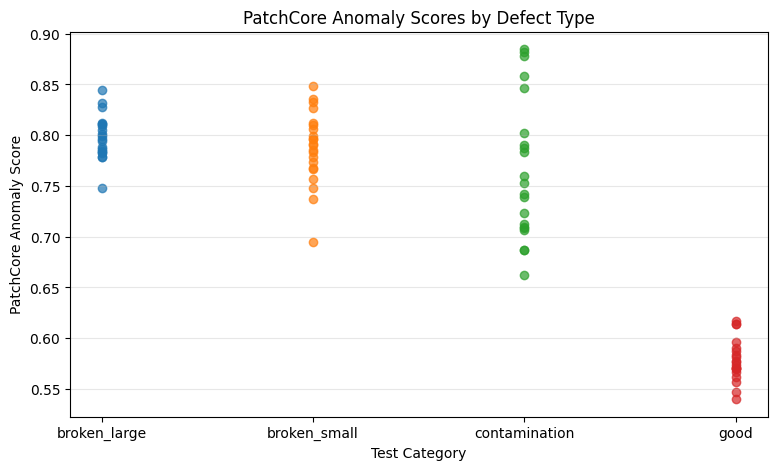

In [ ]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(9, 5)
)

for defect_type in (
    patchcore_results_df[
        "defect_type"
    ].unique()
):

    subset = patchcore_results_df[
        patchcore_results_df[
            "defect_type"
        ] == defect_type
    ]

    plt.scatter(
        [defect_type] * len(subset),
        subset["score"],
        alpha=0.7
    )

plt.ylabel(
    "PatchCore Anomaly Score"
)

plt.xlabel(
    "Test Category"
)

plt.title(
    "PatchCore Anomaly Scores by Defect Type"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [ ]:
patchcore_validation_scores = []

with torch.no_grad():

    for batch in val_loader:

        images = batch["image"].to(device)

        scores, _ = patchcore_score(
            images
        )

        patchcore_validation_scores.extend(
            scores.numpy().tolist()
        )

print(
    "Validation scores:",
    len(patchcore_validation_scores)
)

Validation scores: 20


In [ ]:
PATCHCORE_THRESHOLD = np.percentile(
    patchcore_validation_scores,
    95
)

print(
    f"PatchCore threshold: "
    f"{PATCHCORE_THRESHOLD:.4f}"
)

PatchCore threshold: 0.5988


In [ ]:
patchcore_predictions = [
    1 if score >= PATCHCORE_THRESHOLD else 0
    for score in patchcore_scores
]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

patchcore_accuracy = accuracy_score(
    patchcore_labels,
    patchcore_predictions
)

patchcore_precision = precision_score(
    patchcore_labels,
    patchcore_predictions,
    zero_division=0
)

patchcore_recall = recall_score(
    patchcore_labels,
    patchcore_predictions,
    zero_division=0
)

patchcore_f1 = f1_score(
    patchcore_labels,
    patchcore_predictions,
    zero_division=0
)

print(
    f"Accuracy:  {patchcore_accuracy:.4f}"
)

print(
    f"Precision: {patchcore_precision:.4f}"
)

print(
    f"Recall:    {patchcore_recall:.4f}"
)

print(
    f"F1 Score:  {patchcore_f1:.4f}"
)

Accuracy:  0.9639
Precision: 0.9545
Recall:    1.0000
F1 Score:  0.9767


In [ ]:
from sklearn.metrics import confusion_matrix

patchcore_cm = confusion_matrix(
    patchcore_labels,
    patchcore_predictions
)

print(
    patchcore_cm
)

[[17  3]
 [ 0 63]]


In [ ]:
tn, fp, fn, tp = patchcore_cm.ravel()

print(
    "True Normal:",
    tn
)

print(
    "False Alarm:",
    fp
)

print(
    "Missed Defect:",
    fn
)

print(
    "Detected Defect:",
    tp
)

True Normal: 17
False Alarm: 3
Missed Defect: 0
Detected Defect: 63


In [ ]:
patchcore_metrics = {
    "model": "PatchCore-style",
    "category": "bottle",
    "image_auroc":
        float(patchcore_image_auroc),
    "pixel_auroc":
        float(patchcore_pixel_auroc),
    "threshold":
        float(PATCHCORE_THRESHOLD),
    "accuracy":
        float(patchcore_accuracy),
    "precision":
        float(patchcore_precision),
    "recall":
        float(patchcore_recall),
    "f1":
        float(patchcore_f1),
    "coreset_size":
        int(CORESET_SIZE)
}

patchcore_metrics

{'model': 'PatchCore-style',
 'category': 'bottle',
 'image_auroc': 1.0,
 'pixel_auroc': 0.9819243586892099,
 'threshold': 0.59880111515522,
 'accuracy': 0.963855421686747,
 'precision': 0.9545454545454546,
 'recall': 1.0,
 'f1': 0.9767441860465116,
 'coreset_size': 500}

In [ ]:
patchcore_metrics_df = pd.DataFrame(
    [patchcore_metrics]
)

patchcore_metrics_df.to_csv(
    RESULT_ROOT / "patchcore_bottle_metrics.csv",
    index=False
)

print(
    "PatchCore metrics saved."
)

PatchCore metrics saved.


In [ ]:
comparison_df = pd.DataFrame([
    {
        "Model": "Convolutional Autoencoder",
        "Image AUROC": float(image_auroc),
        "Pixel AUROC": float(pixel_auroc),
        "Accuracy": float(accuracy),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1": float(f1)
    },

    {
        "Model": "PatchCore-style",
        "Image AUROC": float(patchcore_image_auroc),
        "Pixel AUROC": float(patchcore_pixel_auroc),
        "Accuracy": float(patchcore_accuracy),
        "Precision": float(patchcore_precision),
        "Recall": float(patchcore_recall),
        "F1": float(patchcore_f1)
    }
])

comparison_df

,Model,Image AUROC,Pixel AUROC,Accuracy,Precision,Recall,F1
0,Convolutional Autoencoder,0.861111,0.718354,0.819277,0.913793,0.84127,0.876033
1,PatchCore-style,1.000000,0.981924,0.963855,0.954545,1.00000,0.976744


In [ ]:
comparison_path = (
    RESULT_ROOT
    / "bottle_model_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("Saved:", comparison_path)

Saved: /content/drive/MyDrive/VisionInspect/results/bottle_model_comparison.csv


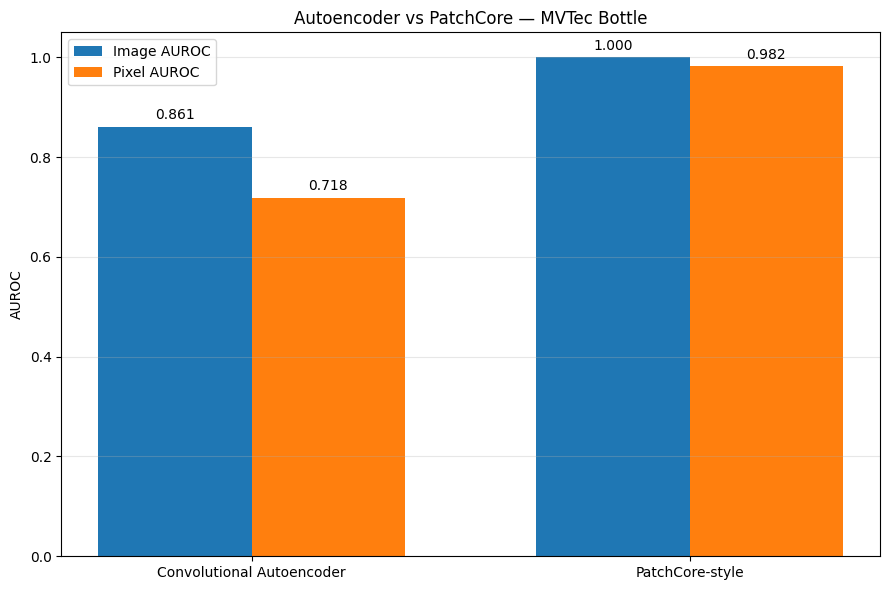

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = comparison_df["Model"]

x = np.arange(len(models))

width = 0.35

fig, ax = plt.subplots(
    figsize=(9, 6)
)

bars1 = ax.bar(
    x - width / 2,
    comparison_df["Image AUROC"],
    width,
    label="Image AUROC"
)

bars2 = ax.bar(
    x + width / 2,
    comparison_df["Pixel AUROC"],
    width,
    label="Pixel AUROC"
)

ax.set_ylabel("AUROC")
ax.set_title(
    "Autoencoder vs PatchCore — MVTec Bottle"
)

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylim(0, 1.05)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.015,
            f"{bar.get_height():.3f}",
            ha="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
FIGURE_ROOT = (
    PROJECT_ROOT
    / "results"
    / "figures"
)

FIGURE_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

figure_path = (
    FIGURE_ROOT
    / "autoencoder_vs_patchcore_auroc.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

print("Saved:", figure_path)

Saved: /content/drive/MyDrive/VisionInspect/results/figures/autoencoder_vs_patchcore_auroc.png


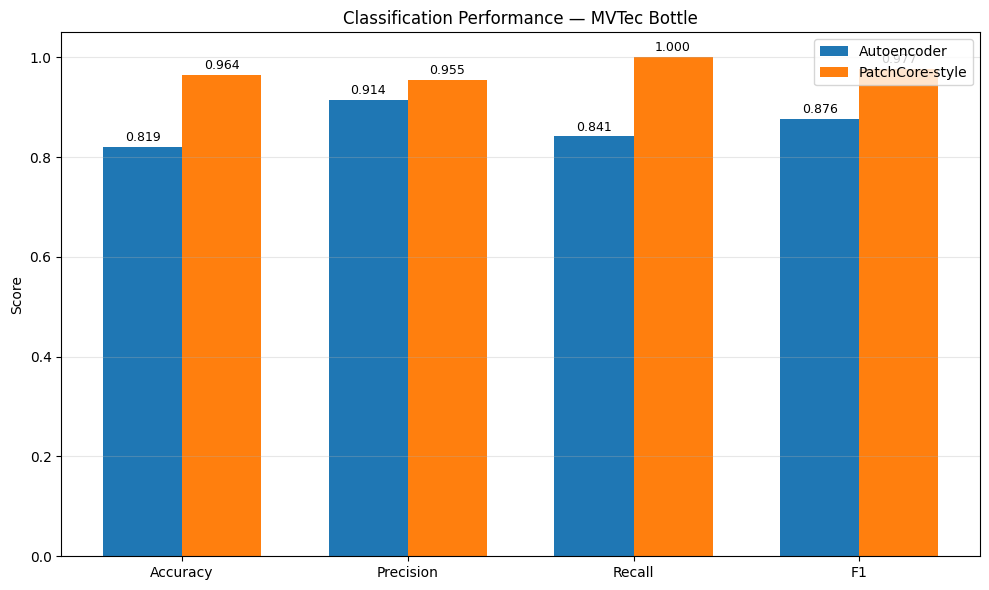

In [ ]:
classification_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
]

x = np.arange(
    len(classification_metrics)
)

width = 0.35

autoencoder_values = [
    accuracy,
    precision,
    recall,
    f1
]

patchcore_values = [
    patchcore_accuracy,
    patchcore_precision,
    patchcore_recall,
    patchcore_f1
]

fig2, ax = plt.subplots(
    figsize=(10, 6)
)

bars1 = ax.bar(
    x - width/2,
    autoencoder_values,
    width,
    label="Autoencoder"
)

bars2 = ax.bar(
    x + width/2,
    patchcore_values,
    width,
    label="PatchCore-style"
)

ax.set_xticks(x)
ax.set_xticklabels(
    classification_metrics
)

ax.set_ylim(0, 1.05)

ax.set_ylabel("Score")

ax.set_title(
    "Classification Performance — MVTec Bottle"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.012,
            f"{bar.get_height():.3f}",
            ha="center",
            fontsize=9
        )

plt.tight_layout()
plt.show()

In [ ]:
classification_figure_path = (
    FIGURE_ROOT
    / "classification_metrics_comparison.png"
)

fig2.savefig(
    classification_figure_path,
    dpi=200,
    bbox_inches="tight"
)

print(
    "Saved:",
    classification_figure_path
)

Saved: /content/drive/MyDrive/VisionInspect/results/figures/classification_metrics_comparison.png


In [ ]:
improvements = {
    "Image AUROC":
        patchcore_image_auroc - image_auroc,

    "Pixel AUROC":
        patchcore_pixel_auroc - pixel_auroc,

    "Accuracy":
        patchcore_accuracy - accuracy,

    "Precision":
        patchcore_precision - precision,

    "Recall":
        patchcore_recall - recall,

    "F1":
        patchcore_f1 - f1
}

for metric, improvement in improvements.items():

    print(
        f"{metric}: "
        f"+{improvement:.4f}"
    )

Image AUROC: +0.1389
Pixel AUROC: +0.2636
Accuracy: +0.1446
Precision: +0.0408
Recall: +0.1587
F1: +0.1007


In [ ]:
HAZELNUT_ROOT = (
    PROJECT_ROOT
    / "data"
    / "hazelnut"
)

print(
    "Hazelnut folder exists:",
    HAZELNUT_ROOT.exists()
)

print(
    "Train exists:",
    (HAZELNUT_ROOT / "train" / "good").exists()
)

print(
    "Test exists:",
    (HAZELNUT_ROOT / "test").exists()
)

print(
    "Ground truth exists:",
    (HAZELNUT_ROOT / "ground_truth").exists()
)

Hazelnut folder exists: True
Train exists: True
Test exists: True
Ground truth exists: True


In [ ]:
for folder in sorted(
    (HAZELNUT_ROOT / "test").iterdir()
):

    if folder.is_dir():

        images = list(
            folder.glob("*.png")
        )

        print(
            folder.name,
            ":",
            len(images)
        )

crack : 18
cut : 17
good : 40
hole : 18
print : 17


In [ ]:
hazelnut_train_dataset = MVTecBottleDataset(
    root=HAZELNUT_ROOT,
    split="train",
    image_transform=image_transform,
    image_size=IMAGE_SIZE
)

hazelnut_test_dataset = MVTecBottleDataset(
    root=HAZELNUT_ROOT,
    split="test",
    image_transform=image_transform,
    image_size=IMAGE_SIZE
)

print(
    "Hazelnut training samples:",
    len(hazelnut_train_dataset)
)

print(
    "Hazelnut test samples:",
    len(hazelnut_test_dataset)
)

Hazelnut training samples: 391
Hazelnut test samples: 110


In [ ]:
hazelnut_val_size = max(
    1,
    int(len(hazelnut_train_dataset) * 0.10)
)

hazelnut_train_size = (
    len(hazelnut_train_dataset)
    - hazelnut_val_size
)

hazelnut_train_subset, hazelnut_val_subset = random_split(
    hazelnut_train_dataset,
    [
        hazelnut_train_size,
        hazelnut_val_size
    ],
    generator=torch.Generator().manual_seed(SEED)
)

print(
    "Hazelnut train:",
    len(hazelnut_train_subset)
)

print(
    "Hazelnut validation:",
    len(hazelnut_val_subset)
)

Hazelnut train: 352
Hazelnut validation: 39


In [ ]:
hazelnut_train_loader = DataLoader(
    hazelnut_train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

hazelnut_val_loader = DataLoader(
    hazelnut_val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

hazelnut_test_loader = DataLoader(
    hazelnut_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(
    "Train batches:",
    len(hazelnut_train_loader)
)

print(
    "Validation batches:",
    len(hazelnut_val_loader)
)

print(
    "Test batches:",
    len(hazelnut_test_loader)
)

Train batches: 44
Validation batches: 5
Test batches: 14


In [ ]:
hazelnut_batch = next(
    iter(hazelnut_train_loader)
)

print(
    "Images:",
    hazelnut_batch["image"].shape
)

print(
    "Labels:",
    hazelnut_batch["label"].shape
)

print(
    "Masks:",
    hazelnut_batch["mask"].shape
)

print(
    "Defect types:",
    hazelnut_batch["defect_type"][:5]
)

Images: torch.Size([8, 3, 256, 256])
Labels: torch.Size([8])
Masks: torch.Size([8, 1, 256, 256])
Defect types: ['good', 'good', 'good', 'good', 'good']


In [ ]:
hazelnut_feature_batches = []

feature_extractor.eval()

with torch.no_grad():

    for batch_number, batch in enumerate(
        hazelnut_train_loader
    ):

        images = batch["image"].to(device)

        # Extract local patch embeddings
        patches, _, _ = extract_patch_embeddings(
            images
        )

        # Project 1536 -> 128
        patches = project_patch_embeddings(
            patches
        )

        # [B, 1024, 128]
        # -> [B*1024, 128]
        patches = patches.reshape(
            -1,
            EMBEDDING_DIM
        )

        hazelnut_feature_batches.append(
            patches.cpu()
        )

        if (batch_number + 1) % 5 == 0:
            print(
                f"Processed "
                f"{batch_number + 1} batches"
            )

Processed 5 batches
Processed 10 batches
Processed 15 batches
Processed 20 batches
Processed 25 batches
Processed 30 batches
Processed 35 batches
Processed 40 batches


In [ ]:
hazelnut_full_memory_candidates = torch.cat(
    hazelnut_feature_batches,
    dim=0
)

print(
    "Hazelnut normal patch features:",
    hazelnut_full_memory_candidates.shape
)

Hazelnut normal patch features: torch.Size([360448, 128])


In [ ]:
if len(hazelnut_full_memory_candidates) > MAX_CANDIDATES:

    generator = torch.Generator()
    generator.manual_seed(SEED)

    indices = torch.randperm(
        len(hazelnut_full_memory_candidates),
        generator=generator
    )[:MAX_CANDIDATES]

    hazelnut_candidate_features = (
        hazelnut_full_memory_candidates[
            indices
        ]
    )

else:

    hazelnut_candidate_features = (
        hazelnut_full_memory_candidates
    )

print(
    "Hazelnut candidates:",
    hazelnut_candidate_features.shape
)

Hazelnut candidates: torch.Size([10000, 128])


In [ ]:
HAZELNUT_CORESET_SIZE = 500

hazelnut_selected_indices = greedy_k_center(
    hazelnut_candidate_features,
    coreset_size=HAZELNUT_CORESET_SIZE,
    device=device
)

Selected 100/500
Selected 200/500
Selected 300/500
Selected 400/500
Selected 500/500


In [ ]:
hazelnut_memory_bank = (
    hazelnut_candidate_features[
        hazelnut_selected_indices
    ]
    .clone()
)

print(
    "Hazelnut memory bank:",
    hazelnut_memory_bank.shape
)

Hazelnut memory bank: torch.Size([500, 128])


In [ ]:
HAZELNUT_MEMORY_PATH = (
    MODEL_ROOT
    / "patchcore_hazelnut_memory.pt"
)

In [ ]:
torch.save(
    {
        "memory_bank":
            hazelnut_memory_bank,

        "projection_matrix":
            projection_matrix.cpu(),

        "embedding_dim":
            EMBEDDING_DIM,

        "coreset_size":
            HAZELNUT_CORESET_SIZE,

        "max_candidates":
            MAX_CANDIDATES,

        "seed":
            SEED
    },
    HAZELNUT_MEMORY_PATH
)

print(
    "Saved:",
    HAZELNUT_MEMORY_PATH
)

print(
    "Exists:",
    HAZELNUT_MEMORY_PATH.exists()
)

Saved: /content/drive/MyDrive/VisionInspect/models/patchcore_hazelnut_memory.pt
Exists: True


In [ ]:
def patchcore_score_with_memory(
    images,
    category_memory_bank
):

    # 1. Extract local CNN patch features
    patches, patch_h, patch_w = (
        extract_patch_embeddings(images)
    )

    # 2. Project 1536 -> 128
    patches = project_patch_embeddings(
        patches
    )

    batch_size = patches.shape[0]

    flat_patches = patches.reshape(
        -1,
        EMBEDDING_DIM
    )

    # Correct category-specific normal memory
    normal_memory = (
        category_memory_bank
        .to(device)
    )

    # 3. Compare every test patch
    # against all normal memory patches
    distances = torch.cdist(
        flat_patches,
        normal_memory
    )

    nearest_distances = (
        distances
        .min(dim=1)
        .values
    )

    # 4. Restore patch grid
    anomaly_maps = nearest_distances.reshape(
        batch_size,
        patch_h,
        patch_w
    )

    # 5. Image-level anomaly score
    flat_maps = anomaly_maps.flatten(
        start_dim=1
    )

    k = max(
        1,
        int(
            flat_maps.shape[1] * 0.01
        )
    )

    image_scores = torch.topk(
        flat_maps,
        k=k,
        dim=1
    ).values.mean(dim=1)

    return (
        image_scores.cpu(),
        anomaly_maps.cpu()
    )

In [ ]:
hazelnut_labels = []
hazelnut_scores = []

hazelnut_pixel_labels = []
hazelnut_pixel_scores = []

hazelnut_defect_types = []

with torch.no_grad():

    for batch in hazelnut_test_loader:

        images = batch["image"].to(device)

        labels = batch["label"]

        masks = batch["mask"]

        image_scores, anomaly_maps = (
            patchcore_score_with_memory(
                images,
                hazelnut_memory_bank
            )
        )

        # 32x32 -> 256x256
        anomaly_maps = upscale_patchcore_map(
            anomaly_maps,
            output_size=IMAGE_SIZE
        )

        hazelnut_scores.extend(
            image_scores.numpy().tolist()
        )

        hazelnut_labels.extend(
            labels.numpy().tolist()
        )

        hazelnut_defect_types.extend(
            batch["defect_type"]
        )

        hazelnut_pixel_scores.append(
            anomaly_maps.numpy().reshape(-1)
        )

        hazelnut_pixel_labels.append(
            masks.numpy().reshape(-1)
        )

In [ ]:
hazelnut_pixel_scores = np.concatenate(
    hazelnut_pixel_scores
)

hazelnut_pixel_labels = np.concatenate(
    hazelnut_pixel_labels
)

print(
    "Hazelnut test images:",
    len(hazelnut_scores)
)

print(
    "Hazelnut pixels:",
    len(hazelnut_pixel_scores)
)

Hazelnut test images: 110
Hazelnut pixels: 7208960


In [ ]:
hazelnut_image_auroc = roc_auc_score(
    hazelnut_labels,
    hazelnut_scores
)

print(
    f"Hazelnut Image AUROC: "
    f"{hazelnut_image_auroc:.4f}"
)

Hazelnut Image AUROC: 1.0000


In [ ]:
hazelnut_pixel_auroc = roc_auc_score(
    hazelnut_pixel_labels,
    hazelnut_pixel_scores
)

print(
    f"Hazelnut Pixel AUROC: "
    f"{hazelnut_pixel_auroc:.4f}"
)

Hazelnut Pixel AUROC: 0.9841


In [ ]:
hazelnut_results_df = pd.DataFrame({
    "label": hazelnut_labels,
    "score": hazelnut_scores,
    "defect_type": hazelnut_defect_types
})

hazelnut_results_df.groupby(
    "defect_type"
)["score"].agg(
    [
        "mean",
        "std",
        "min",
        "max",
        "count"
    ]
)

,mean,std,min,max,count
defect_type,,,,,
crack,0.829771,0.028177,0.775381,0.886200,18
cut,0.835248,0.025775,0.790752,0.876788,17
good,0.730025,0.014318,0.707163,0.766732,40
hole,0.832996,0.019653,0.788157,0.860051,18
print,0.842295,0.033540,0.780337,0.934506,17


In [ ]:
hazelnut_validation_scores = []

with torch.no_grad():

    for batch in hazelnut_val_loader:

        images = batch["image"].to(device)

        scores, _ = (
            patchcore_score_with_memory(
                images,
                hazelnut_memory_bank
            )
        )

        hazelnut_validation_scores.extend(
            scores.numpy().tolist()
        )

print(
    "Hazelnut validation images:",
    len(hazelnut_validation_scores)
)

Hazelnut validation images: 39


In [ ]:
HAZELNUT_THRESHOLD = np.percentile(
    hazelnut_validation_scores,
    95
)

print(
    f"Hazelnut threshold: "
    f"{HAZELNUT_THRESHOLD:.4f}"
)

Hazelnut threshold: 0.7508


In [ ]:
hazelnut_predictions = [
    1 if score >= HAZELNUT_THRESHOLD else 0
    for score in hazelnut_scores
]

In [ ]:
hazelnut_accuracy = accuracy_score(
    hazelnut_labels,
    hazelnut_predictions
)

hazelnut_precision = precision_score(
    hazelnut_labels,
    hazelnut_predictions,
    zero_division=0
)

hazelnut_recall = recall_score(
    hazelnut_labels,
    hazelnut_predictions,
    zero_division=0
)

hazelnut_f1 = f1_score(
    hazelnut_labels,
    hazelnut_predictions,
    zero_division=0
)

print(
    f"Accuracy:  {hazelnut_accuracy:.4f}"
)

print(
    f"Precision: {hazelnut_precision:.4f}"
)

print(
    f"Recall:    {hazelnut_recall:.4f}"
)

print(
    f"F1 Score:  {hazelnut_f1:.4f}"
)

Accuracy:  0.9636
Precision: 0.9459
Recall:    1.0000
F1 Score:  0.9722


In [ ]:
hazelnut_cm = confusion_matrix(
    hazelnut_labels,
    hazelnut_predictions
)

print(hazelnut_cm)

[[36  4]
 [ 0 70]]


In [ ]:
tn, fp, fn, tp = (
    hazelnut_cm.ravel()
)

print("True Normal:", tn)
print("False Alarm:", fp)
print("Missed Defect:", fn)
print("Detected Defect:", tp)

True Normal: 36
False Alarm: 4
Missed Defect: 0
Detected Defect: 70


In [ ]:
hazelnut_metrics = {
    "model": "PatchCore-style",
    "category": "hazelnut",
    "image_auroc":
        float(hazelnut_image_auroc),
    "pixel_auroc":
        float(hazelnut_pixel_auroc),
    "threshold":
        float(HAZELNUT_THRESHOLD),
    "accuracy":
        float(hazelnut_accuracy),
    "precision":
        float(hazelnut_precision),
    "recall":
        float(hazelnut_recall),
    "f1":
        float(hazelnut_f1),
    "coreset_size":
        int(HAZELNUT_CORESET_SIZE)
}

hazelnut_metrics

{'model': 'PatchCore-style',
 'category': 'hazelnut',
 'image_auroc': 1.0,
 'pixel_auroc': 0.9840863189104297,
 'threshold': 0.7508410274982452,
 'accuracy': 0.9636363636363636,
 'precision': 0.9459459459459459,
 'recall': 1.0,
 'f1': 0.9722222222222222,
 'coreset_size': 500}

In [ ]:
pd.DataFrame(
    [hazelnut_metrics]
).to_csv(
    RESULT_ROOT
    / "patchcore_hazelnut_metrics.csv",
    index=False
)

print(
    "Hazelnut metrics saved."
)

Hazelnut metrics saved.


In [ ]:
bottle_metrics_df = pd.read_csv(
    RESULT_ROOT / "patchcore_bottle_metrics.csv"
)

hazelnut_metrics_df = pd.read_csv(
    RESULT_ROOT / "patchcore_hazelnut_metrics.csv"
)

category_comparison_df = pd.concat(
    [
        bottle_metrics_df,
        hazelnut_metrics_df
    ],
    ignore_index=True
)

category_comparison_df

,model,category,image_auroc,pixel_auroc,threshold,accuracy,precision,recall,f1,coreset_size
0,PatchCore-style,bottle,1.0,0.981924,0.598801,0.963855,0.954545,1.0,0.976744,500
1,PatchCore-style,hazelnut,1.0,0.984086,0.750841,0.963636,0.945946,1.0,0.972222,500


In [ ]:
category_summary = category_comparison_df[
    [
        "category",
        "image_auroc",
        "pixel_auroc",
        "accuracy",
        "precision",
        "recall",
        "f1"
    ]
]

category_summary

,category,image_auroc,pixel_auroc,accuracy,precision,recall,f1
0,bottle,1.0,0.981924,0.963855,0.954545,1.0,0.976744
1,hazelnut,1.0,0.984086,0.963636,0.945946,1.0,0.972222


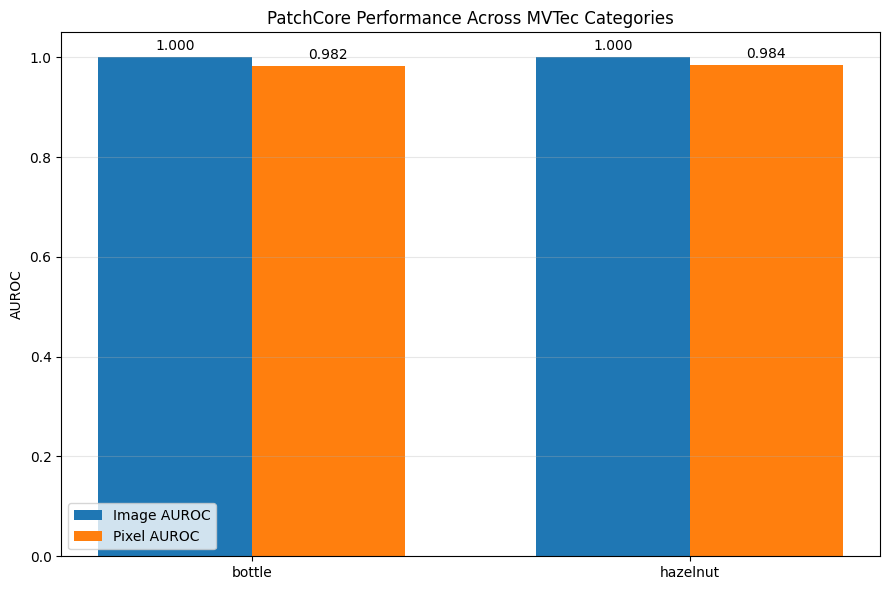

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

categories = category_summary["category"]

x = np.arange(len(categories))

width = 0.35

fig, ax = plt.subplots(
    figsize=(9, 6)
)

bars1 = ax.bar(
    x - width / 2,
    category_summary["image_auroc"],
    width,
    label="Image AUROC"
)

bars2 = ax.bar(
    x + width / 2,
    category_summary["pixel_auroc"],
    width,
    label="Pixel AUROC"
)

ax.set_xticks(x)
ax.set_xticklabels(categories)

ax.set_ylim(0, 1.05)

ax.set_ylabel("AUROC")

ax.set_title(
    "PatchCore Performance Across MVTec Categories"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

for bars in [bars1, bars2]:

    for bar in bars:

        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.015,
            f"{bar.get_height():.3f}",
            ha="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
category_figure_path = (
    FIGURE_ROOT
    / "patchcore_category_comparison.png"
)

fig.savefig(
    category_figure_path,
    dpi=200,
    bbox_inches="tight"
)

print(
    "Saved:",
    category_figure_path
)

Saved: /content/drive/MyDrive/VisionInspect/results/figures/patchcore_category_comparison.png


In [ ]:
average_image_auroc = (
    category_summary["image_auroc"].mean()
)

average_pixel_auroc = (
    category_summary["pixel_auroc"].mean()
)

average_f1 = (
    category_summary["f1"].mean()
)

print(
    f"Average Image AUROC: "
    f"{average_image_auroc:.4f}"
)

print(
    f"Average Pixel AUROC: "
    f"{average_pixel_auroc:.4f}"
)

print(
    f"Average F1: "
    f"{average_f1:.4f}"
)

Average Image AUROC: 1.0000
Average Pixel AUROC: 0.9830
Average F1: 0.9745


In [ ]:
TILE_ROOT = (
    PROJECT_ROOT
    / "data"
    / "tile"
)

print(
    "Tile folder exists:",
    TILE_ROOT.exists()
)

print(
    "Train exists:",
    (TILE_ROOT / "train" / "good").exists()
)

print(
    "Test exists:",
    (TILE_ROOT / "test").exists()
)

print(
    "Ground truth exists:",
    (TILE_ROOT / "ground_truth").exists()
)

Tile folder exists: True
Train exists: True
Test exists: True
Ground truth exists: True


In [ ]:
for folder in sorted(
    (TILE_ROOT / "test").iterdir()
):

    if folder.is_dir():

        images = list(
            folder.glob("*.png")
        )

        print(
            f"{folder.name}: "
            f"{len(images)} images"
        )

crack: 17 images
glue_strip: 18 images
good: 33 images
gray_stroke: 16 images
oil: 18 images
rough: 15 images


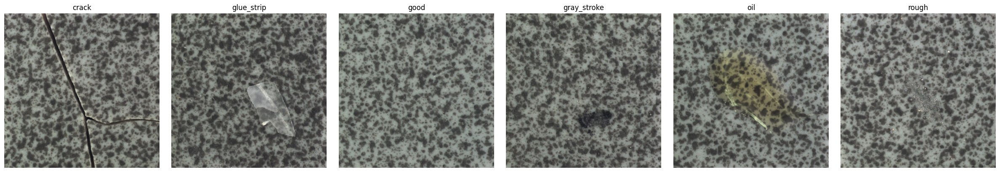

In [ ]:
tile_test_root = (
    TILE_ROOT / "test"
)

tile_test_folders = [
    folder
    for folder in sorted(
        tile_test_root.iterdir()
    )
    if folder.is_dir()
]

fig, axes = plt.subplots(
    1,
    len(tile_test_folders),
    figsize=(
        4 * len(tile_test_folders),
        4
    )
)

for ax, folder in zip(
    axes,
    tile_test_folders
):

    images = sorted(
        folder.glob("*.png")
    )

    image = Image.open(
        images[0]
    ).convert("RGB")

    ax.imshow(image)
    ax.set_title(folder.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

VISIONINSPECT — TILE PATCHCORE EXPERIMENT

[1/9] Configuration ready
Tile path: /content/drive/MyDrive/VisionInspect/data/tile
Tile exists: True

[2/9] Tile datasets created
Training images: 207
Validation images: 23
Test images: 117
Feature batches processed: 5
Feature batches processed: 10
Feature batches processed: 15
Feature batches processed: 20
Feature batches processed: 25

[3/9] Feature extraction complete
All Tile normal patches: torch.Size([211968, 128])

[4/9] Candidate pool created
Candidate features: torch.Size([10000, 128])

Building Tile coreset...
Selected 100/500
Selected 200/500
Selected 300/500
Selected 400/500
Selected 500/500

[5/9] Tile memory bank built
Memory bank: torch.Size([500, 128])

[6/9] Memory bank saved
/content/drive/MyDrive/VisionInspect/models/patchcore_tile_memory.pt

[7/9] Test evaluation complete
Image AUROC: 1.0000
Pixel AUROC: 0.9428

[8/9] Classification metrics
Threshold: 0.6645
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  

,category,image_auroc,pixel_auroc,accuracy,precision,recall,f1
0,bottle,1.0,0.981924,0.963855,0.954545,1.0,0.976744
1,hazelnut,1.0,0.984086,0.963636,0.945946,1.0,0.972222
2,tile,1.0,0.942843,1.000000,1.000000,1.0,1.000000



Average Image AUROC: 1.0
Average Pixel AUROC: 0.9696
Average F1: 0.983


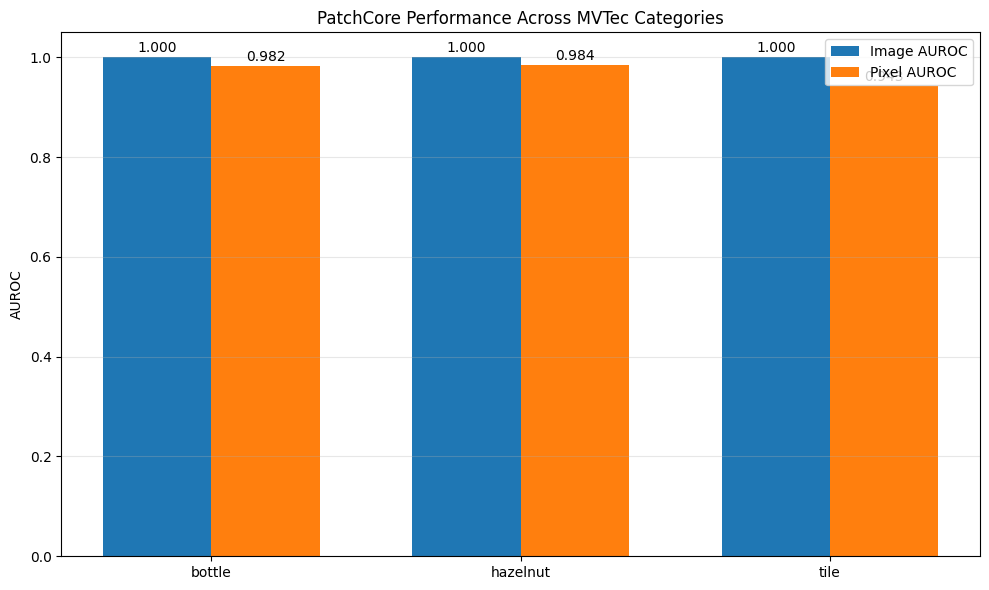


[9/9] COMPLETE ✅
Metrics saved to: /content/drive/MyDrive/VisionInspect/results
Graph saved to: /content/drive/MyDrive/VisionInspect/results/figures/patchcore_three_category_comparison.png


In [ ]:
# ============================================================
# STEP 23G — COMPLETE TILE PATCHCORE PIPELINE
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 60)
print("VISIONINSPECT — TILE PATCHCORE EXPERIMENT")
print("=" * 60)


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

TILE_ROOT = (
    PROJECT_ROOT
    / "data"
    / "tile"
)

TILE_CORESET_SIZE = 500

print("\n[1/9] Configuration ready")

print(
    "Tile path:",
    TILE_ROOT
)

print(
    "Tile exists:",
    TILE_ROOT.exists()
)


# ------------------------------------------------------------
# 2. CREATE TILE DATASETS
# ------------------------------------------------------------

tile_train_dataset = MVTecBottleDataset(
    root=TILE_ROOT,
    split="train",
    image_transform=image_transform,
    image_size=IMAGE_SIZE
)

tile_test_dataset = MVTecBottleDataset(
    root=TILE_ROOT,
    split="test",
    image_transform=image_transform,
    image_size=IMAGE_SIZE
)


tile_val_size = max(
    1,
    int(
        len(tile_train_dataset)
        * 0.10
    )
)

tile_train_size = (
    len(tile_train_dataset)
    - tile_val_size
)


tile_train_subset, tile_val_subset = random_split(
    tile_train_dataset,
    [
        tile_train_size,
        tile_val_size
    ],
    generator=
    torch.Generator()
    .manual_seed(SEED)
)


tile_train_loader = DataLoader(
    tile_train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

tile_val_loader = DataLoader(
    tile_val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

tile_test_loader = DataLoader(
    tile_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("\n[2/9] Tile datasets created")

print(
    "Training images:",
    len(tile_train_subset)
)

print(
    "Validation images:",
    len(tile_val_subset)
)

print(
    "Test images:",
    len(tile_test_dataset)
)


# ------------------------------------------------------------
# 3. EXTRACT NORMAL TILE FEATURES
# ------------------------------------------------------------

tile_feature_batches = []

feature_extractor.eval()

with torch.no_grad():

    for batch_number, batch in enumerate(
        tile_train_loader
    ):

        images = batch[
            "image"
        ].to(device)

        patches, _, _ = (
            extract_patch_embeddings(
                images
            )
        )

        patches = (
            project_patch_embeddings(
                patches
            )
        )

        patches = patches.reshape(
            -1,
            EMBEDDING_DIM
        )

        tile_feature_batches.append(
            patches.cpu()
        )

        if (
            (batch_number + 1) % 5
            == 0
        ):

            print(
                "Feature batches processed:",
                batch_number + 1
            )


tile_full_memory_candidates = (
    torch.cat(
        tile_feature_batches,
        dim=0
    )
)


print("\n[3/9] Feature extraction complete")

print(
    "All Tile normal patches:",
    tile_full_memory_candidates.shape
)


# ------------------------------------------------------------
# 4. REDUCE TO MAX 10,000 CANDIDATES
# ------------------------------------------------------------

generator = torch.Generator()

generator.manual_seed(
    SEED
)


if (
    len(tile_full_memory_candidates)
    >
    MAX_CANDIDATES
):

    indices = torch.randperm(
        len(
            tile_full_memory_candidates
        ),
        generator=generator
    )[:MAX_CANDIDATES]

    tile_candidate_features = (
        tile_full_memory_candidates[
            indices
        ]
    )

else:

    tile_candidate_features = (
        tile_full_memory_candidates
    )


print("\n[4/9] Candidate pool created")

print(
    "Candidate features:",
    tile_candidate_features.shape
)


# ------------------------------------------------------------
# 5. BUILD 500-PATCH CORESET
# ------------------------------------------------------------

print(
    "\nBuilding Tile coreset..."
)

tile_selected_indices = (
    greedy_k_center(
        tile_candidate_features,
        coreset_size=
        TILE_CORESET_SIZE,
        device=device
    )
)


tile_memory_bank = (
    tile_candidate_features[
        tile_selected_indices
    ]
    .clone()
)


print("\n[5/9] Tile memory bank built")

print(
    "Memory bank:",
    tile_memory_bank.shape
)


# ------------------------------------------------------------
# 6. SAVE TILE MEMORY BANK
# ------------------------------------------------------------

TILE_MEMORY_PATH = (
    MODEL_ROOT
    / "patchcore_tile_memory.pt"
)


torch.save(
    {
        "memory_bank":
            tile_memory_bank,

        "projection_matrix":
            projection_matrix.cpu(),

        "embedding_dim":
            EMBEDDING_DIM,

        "coreset_size":
            TILE_CORESET_SIZE,

        "max_candidates":
            MAX_CANDIDATES,

        "seed":
            SEED
    },
    TILE_MEMORY_PATH
)


print("\n[6/9] Memory bank saved")

print(
    TILE_MEMORY_PATH
)


# ------------------------------------------------------------
# 7. EVALUATE TILE TEST SET
# ------------------------------------------------------------

tile_labels = []
tile_scores = []

tile_pixel_labels = []
tile_pixel_scores = []

tile_defect_types = []


with torch.no_grad():

    for batch in tile_test_loader:

        images = batch[
            "image"
        ].to(device)

        labels = batch[
            "label"
        ]

        masks = batch[
            "mask"
        ]


        image_scores, anomaly_maps = (
            patchcore_score_with_memory(
                images,
                tile_memory_bank
            )
        )


        anomaly_maps = (
            upscale_patchcore_map(
                anomaly_maps,
                output_size=IMAGE_SIZE
            )
        )


        tile_scores.extend(
            image_scores
            .numpy()
            .tolist()
        )

        tile_labels.extend(
            labels
            .numpy()
            .tolist()
        )

        tile_defect_types.extend(
            batch[
                "defect_type"
            ]
        )


        tile_pixel_scores.append(
            anomaly_maps
            .numpy()
            .reshape(-1)
        )

        tile_pixel_labels.append(
            masks
            .numpy()
            .reshape(-1)
        )


tile_pixel_scores = np.concatenate(
    tile_pixel_scores
)

tile_pixel_labels = np.concatenate(
    tile_pixel_labels
)


tile_image_auroc = roc_auc_score(
    tile_labels,
    tile_scores
)

tile_pixel_auroc = roc_auc_score(
    tile_pixel_labels,
    tile_pixel_scores
)


print("\n[7/9] Test evaluation complete")

print(
    f"Image AUROC: "
    f"{tile_image_auroc:.4f}"
)

print(
    f"Pixel AUROC: "
    f"{tile_pixel_auroc:.4f}"
)


# ------------------------------------------------------------
# 8. VALIDATION THRESHOLD + CLASSIFICATION METRICS
# ------------------------------------------------------------

tile_validation_scores = []


with torch.no_grad():

    for batch in tile_val_loader:

        images = batch[
            "image"
        ].to(device)

        scores, _ = (
            patchcore_score_with_memory(
                images,
                tile_memory_bank
            )
        )

        tile_validation_scores.extend(
            scores
            .numpy()
            .tolist()
        )


TILE_THRESHOLD = np.percentile(
    tile_validation_scores,
    95
)


tile_predictions = [

    1
    if score >= TILE_THRESHOLD
    else 0

    for score
    in tile_scores
]


tile_accuracy = accuracy_score(
    tile_labels,
    tile_predictions
)

tile_precision = precision_score(
    tile_labels,
    tile_predictions,
    zero_division=0
)

tile_recall = recall_score(
    tile_labels,
    tile_predictions,
    zero_division=0
)

tile_f1 = f1_score(
    tile_labels,
    tile_predictions,
    zero_division=0
)


tile_cm = confusion_matrix(
    tile_labels,
    tile_predictions
)


tn, fp, fn, tp = (
    tile_cm.ravel()
)


print("\n[8/9] Classification metrics")

print(
    f"Threshold: "
    f"{TILE_THRESHOLD:.4f}"
)

print(
    f"Accuracy:  "
    f"{tile_accuracy:.4f}"
)

print(
    f"Precision: "
    f"{tile_precision:.4f}"
)

print(
    f"Recall:    "
    f"{tile_recall:.4f}"
)

print(
    f"F1 Score:  "
    f"{tile_f1:.4f}"
)


print("\nConfusion Matrix")

print(
    "True Normal:",
    tn
)

print(
    "False Alarm:",
    fp
)

print(
    "Missed Defect:",
    fn
)

print(
    "Detected Defect:",
    tp
)


# ------------------------------------------------------------
# 9. SAVE TILE METRICS
# ------------------------------------------------------------

tile_metrics = {

    "model":
        "PatchCore-style",

    "category":
        "tile",

    "image_auroc":
        float(
            tile_image_auroc
        ),

    "pixel_auroc":
        float(
            tile_pixel_auroc
        ),

    "threshold":
        float(
            TILE_THRESHOLD
        ),

    "accuracy":
        float(
            tile_accuracy
        ),

    "precision":
        float(
            tile_precision
        ),

    "recall":
        float(
            tile_recall
        ),

    "f1":
        float(
            tile_f1
        ),

    "coreset_size":
        int(
            TILE_CORESET_SIZE
        )
}


pd.DataFrame(
    [tile_metrics]
).to_csv(

    RESULT_ROOT
    / "patchcore_tile_metrics.csv",

    index=False
)


# ------------------------------------------------------------
# 10. COMBINE BOTTLE + HAZELNUT + TILE
# ------------------------------------------------------------

bottle_df = pd.read_csv(
    RESULT_ROOT
    / "patchcore_bottle_metrics.csv"
)

hazelnut_df = pd.read_csv(
    RESULT_ROOT
    / "patchcore_hazelnut_metrics.csv"
)

tile_df = pd.read_csv(
    RESULT_ROOT
    / "patchcore_tile_metrics.csv"
)


three_category_df = pd.concat(
    [
        bottle_df,
        hazelnut_df,
        tile_df
    ],
    ignore_index=True
)


three_category_df.to_csv(

    RESULT_ROOT
    / "patchcore_three_category_results.csv",

    index=False
)


# ------------------------------------------------------------
# 11. PRINT FINAL TABLE
# ------------------------------------------------------------

summary_columns = [

    "category",
    "image_auroc",
    "pixel_auroc",
    "accuracy",
    "precision",
    "recall",
    "f1"
]


print("\n" + "=" * 60)

print(
    "FINAL THREE-CATEGORY RESULTS"
)

print("=" * 60)

display(
    three_category_df[
        summary_columns
    ]
)


print(
    "\nAverage Image AUROC:",
    round(
        three_category_df[
            "image_auroc"
        ].mean(),
        4
    )
)

print(
    "Average Pixel AUROC:",
    round(
        three_category_df[
            "pixel_auroc"
        ].mean(),
        4
    )
)

print(
    "Average F1:",
    round(
        three_category_df[
            "f1"
        ].mean(),
        4
    )
)


# ------------------------------------------------------------
# 12. SAVE THREE-CATEGORY GRAPH
# ------------------------------------------------------------

categories = (
    three_category_df[
        "category"
    ]
)

x = np.arange(
    len(categories)
)

width = 0.35


fig, ax = plt.subplots(
    figsize=(10, 6)
)


bars1 = ax.bar(

    x - width / 2,

    three_category_df[
        "image_auroc"
    ],

    width,

    label="Image AUROC"
)


bars2 = ax.bar(

    x + width / 2,

    three_category_df[
        "pixel_auroc"
    ],

    width,

    label="Pixel AUROC"
)


ax.set_xticks(x)

ax.set_xticklabels(
    categories
)

ax.set_ylim(
    0,
    1.05
)

ax.set_ylabel(
    "AUROC"
)

ax.set_title(
    "PatchCore Performance Across MVTec Categories"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)


for bars in [
    bars1,
    bars2
]:

    for bar in bars:

        ax.text(

            bar.get_x()
            +
            bar.get_width() / 2,

            bar.get_height()
            + 0.01,

            f"{bar.get_height():.3f}",

            ha="center"
        )


plt.tight_layout()


three_category_figure = (

    FIGURE_ROOT
    / "patchcore_three_category_comparison.png"

)


plt.savefig(

    three_category_figure,

    dpi=200,

    bbox_inches="tight"
)


plt.show()


print("\n[9/9] COMPLETE ✅")

print(
    "Metrics saved to:",
    RESULT_ROOT
)

print(
    "Graph saved to:",
    three_category_figure
)

print("=" * 60)

VISIONINSPECT — PATCHCORE CORESET ABLATION
Category: Bottle

[1/5] Extracting Bottle normal features...
All normal patches: torch.Size([193536, 128])
Candidate pool: torch.Size([10000, 128])

-----------------------------------------------------------------
Testing coreset size: 100
-----------------------------------------------------------------
Selected 100/100
Image AUROC: 1.0000
Pixel AUROC: 0.9690
Inference: 10.62 ms/image
Memory bank: 0.049 MB

-----------------------------------------------------------------
Testing coreset size: 250
-----------------------------------------------------------------
Selected 100/250
Selected 200/250
Selected 250/250
Image AUROC: 1.0000
Pixel AUROC: 0.9793
Inference: 10.38 ms/image
Memory bank: 0.122 MB

-----------------------------------------------------------------
Testing coreset size: 500
-----------------------------------------------------------------
Selected 100/500
Selected 200/500
Selected 300/500
Selected 400/500
Selected 500/500
Ima

,coreset_size,image_auroc,pixel_auroc,inference_ms_per_image,memory_mb,coreset_build_seconds
0,100,1.0,0.969026,10.616515,0.048828,0.014880
1,250,1.0,0.979272,10.381443,0.122070,0.038107
2,500,1.0,0.982357,10.590117,0.244141,0.073018
3,1000,1.0,0.984018,11.866345,0.488281,0.141074



Saved CSV: /content/drive/MyDrive/VisionInspect/results/bottle_coreset_ablation.csv


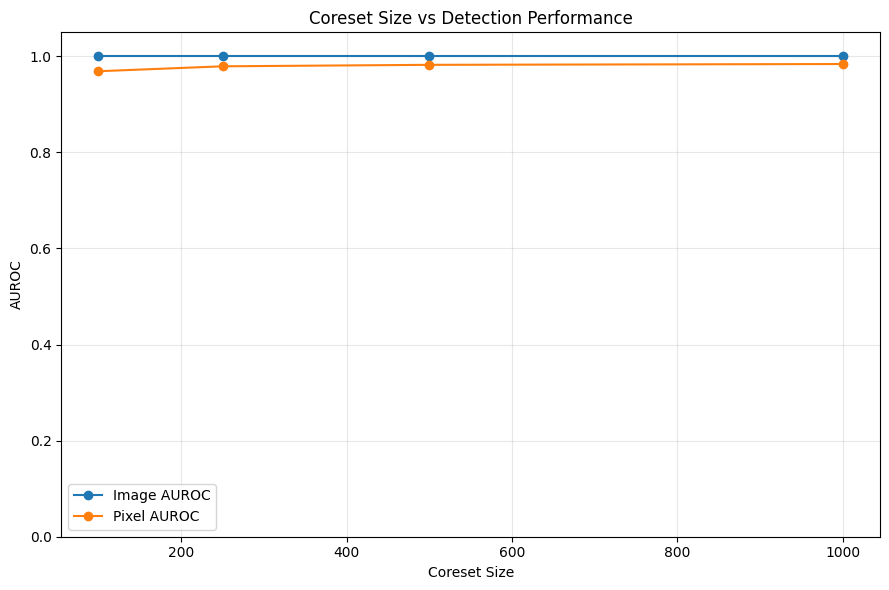

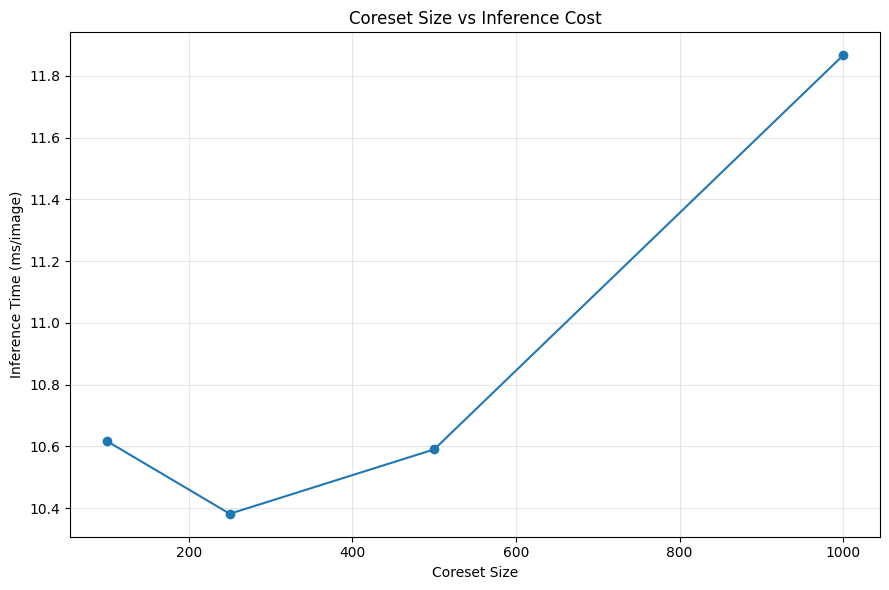


BEST PIXEL-LOCALIZATION CONFIGURATION
Coreset size: 1000
Image AUROC: 1.0
Pixel AUROC: 0.984
Inference: 11.87 ms/image

STEP 24 COMPLETE ✅


In [ ]:
# ============================================================
# STEP 24 — PATCHCORE CORESET ABLATION STUDY (BOTTLE)
# ============================================================

import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score


print("=" * 65)
print("VISIONINSPECT — PATCHCORE CORESET ABLATION")
print("Category: Bottle")
print("=" * 65)


# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

CORESET_SIZES = [
    100,
    250,
    500,
    1000
]

ablation_results = []


# ------------------------------------------------------------
# REBUILD BOTTLE NORMAL FEATURE CANDIDATES
# ------------------------------------------------------------

print("\n[1/5] Extracting Bottle normal features...")

bottle_feature_batches = []

feature_extractor.eval()

with torch.no_grad():

    for batch_number, batch in enumerate(
        train_loader
    ):

        images = batch["image"].to(device)

        patches, _, _ = (
            extract_patch_embeddings(
                images
            )
        )

        patches = (
            project_patch_embeddings(
                patches
            )
        )

        patches = patches.reshape(
            -1,
            EMBEDDING_DIM
        )

        bottle_feature_batches.append(
            patches.cpu()
        )


bottle_all_features = torch.cat(
    bottle_feature_batches,
    dim=0
)


print(
    "All normal patches:",
    bottle_all_features.shape
)


# ------------------------------------------------------------
# CREATE SAME 10,000-CANDIDATE POOL FOR ALL EXPERIMENTS
# ------------------------------------------------------------

generator = torch.Generator()

generator.manual_seed(
    SEED
)


if (
    len(bottle_all_features)
    >
    MAX_CANDIDATES
):

    candidate_indices = torch.randperm(
        len(bottle_all_features),
        generator=generator
    )[:MAX_CANDIDATES]

    bottle_ablation_candidates = (
        bottle_all_features[
            candidate_indices
        ]
    )

else:

    bottle_ablation_candidates = (
        bottle_all_features
    )


print(
    "Candidate pool:",
    bottle_ablation_candidates.shape
)


# ------------------------------------------------------------
# LOOP THROUGH CORESETS
# ------------------------------------------------------------

for coreset_size in CORESET_SIZES:

    print("\n" + "-" * 65)

    print(
        f"Testing coreset size: "
        f"{coreset_size}"
    )

    print("-" * 65)


    # --------------------------------------------------------
    # BUILD MEMORY BANK
    # --------------------------------------------------------

    start_build = time.perf_counter()


    selected_indices = (
        greedy_k_center(
            bottle_ablation_candidates,
            coreset_size=coreset_size,
            device=device
        )
    )


    current_memory_bank = (
        bottle_ablation_candidates[
            selected_indices
        ]
        .clone()
    )


    build_time = (
        time.perf_counter()
        -
        start_build
    )


    # --------------------------------------------------------
    # TEST SET
    # --------------------------------------------------------

    image_labels = []
    image_scores = []

    pixel_labels = []
    pixel_scores = []

    inference_times = []


    with torch.no_grad():

        for batch in test_loader:

            images = batch[
                "image"
            ].to(device)

            labels = batch[
                "label"
            ]

            masks = batch[
                "mask"
            ]


            # GPU synchronization gives more accurate timing
            if torch.cuda.is_available():
                torch.cuda.synchronize()


            inference_start = (
                time.perf_counter()
            )


            scores, anomaly_maps = (
                patchcore_score_with_memory(
                    images,
                    current_memory_bank
                )
            )


            if torch.cuda.is_available():
                torch.cuda.synchronize()


            inference_end = (
                time.perf_counter()
            )


            batch_time = (
                inference_end
                -
                inference_start
            )


            inference_times.append(
                batch_time
                /
                images.shape[0]
            )


            anomaly_maps = (
                upscale_patchcore_map(
                    anomaly_maps,
                    output_size=
                    IMAGE_SIZE
                )
            )


            image_labels.extend(
                labels
                .numpy()
                .tolist()
            )


            image_scores.extend(
                scores
                .numpy()
                .tolist()
            )


            pixel_labels.append(
                masks
                .numpy()
                .reshape(-1)
            )


            pixel_scores.append(
                anomaly_maps
                .numpy()
                .reshape(-1)
            )


    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    pixel_labels = np.concatenate(
        pixel_labels
    )

    pixel_scores = np.concatenate(
        pixel_scores
    )


    current_image_auroc = (
        roc_auc_score(
            image_labels,
            image_scores
        )
    )


    current_pixel_auroc = (
        roc_auc_score(
            pixel_labels,
            pixel_scores
        )
    )


    average_inference_seconds = (
        np.mean(
            inference_times
        )
    )


    average_inference_ms = (
        average_inference_seconds
        * 1000
    )


    # Memory bank storage estimate
    memory_bytes = (
        current_memory_bank.numel()
        *
        current_memory_bank.element_size()
    )

    memory_mb = (
        memory_bytes
        /
        (1024 ** 2)
    )


    ablation_results.append(
        {
            "coreset_size":
                coreset_size,

            "image_auroc":
                float(
                    current_image_auroc
                ),

            "pixel_auroc":
                float(
                    current_pixel_auroc
                ),

            "inference_ms_per_image":
                float(
                    average_inference_ms
                ),

            "memory_mb":
                float(
                    memory_mb
                ),

            "coreset_build_seconds":
                float(
                    build_time
                )
        }
    )


    print(
        f"Image AUROC: "
        f"{current_image_auroc:.4f}"
    )

    print(
        f"Pixel AUROC: "
        f"{current_pixel_auroc:.4f}"
    )

    print(
        f"Inference: "
        f"{average_inference_ms:.2f} ms/image"
    )

    print(
        f"Memory bank: "
        f"{memory_mb:.3f} MB"
    )


# ------------------------------------------------------------
# CREATE RESULTS TABLE
# ------------------------------------------------------------

ablation_df = pd.DataFrame(
    ablation_results
)


print("\n" + "=" * 65)

print(
    "CORESET ABLATION RESULTS"
)

print("=" * 65)


display(
    ablation_df
)


# ------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------

ablation_csv_path = (
    RESULT_ROOT
    / "bottle_coreset_ablation.csv"
)


ablation_df.to_csv(
    ablation_csv_path,
    index=False
)


print(
    "\nSaved CSV:",
    ablation_csv_path
)


# ------------------------------------------------------------
# GRAPH 1 — AUROC VS CORESETS
# ------------------------------------------------------------

fig1, ax1 = plt.subplots(
    figsize=(9, 6)
)


ax1.plot(
    ablation_df[
        "coreset_size"
    ],
    ablation_df[
        "image_auroc"
    ],
    marker="o",
    label="Image AUROC"
)


ax1.plot(
    ablation_df[
        "coreset_size"
    ],
    ablation_df[
        "pixel_auroc"
    ],
    marker="o",
    label="Pixel AUROC"
)


ax1.set_xlabel(
    "Coreset Size"
)

ax1.set_ylabel(
    "AUROC"
)

ax1.set_title(
    "Coreset Size vs Detection Performance"
)

ax1.set_ylim(
    0,
    1.05
)

ax1.grid(
    alpha=0.3
)

ax1.legend()


plt.tight_layout()


performance_graph_path = (
    FIGURE_ROOT
    / "coreset_ablation_performance.png"
)


fig1.savefig(
    performance_graph_path,
    dpi=200,
    bbox_inches="tight"
)


plt.show()


# ------------------------------------------------------------
# GRAPH 2 — INFERENCE SPEED
# ------------------------------------------------------------

fig2, ax2 = plt.subplots(
    figsize=(9, 6)
)


ax2.plot(
    ablation_df[
        "coreset_size"
    ],
    ablation_df[
        "inference_ms_per_image"
    ],
    marker="o"
)


ax2.set_xlabel(
    "Coreset Size"
)

ax2.set_ylabel(
    "Inference Time (ms/image)"
)

ax2.set_title(
    "Coreset Size vs Inference Cost"
)

ax2.grid(
    alpha=0.3
)


plt.tight_layout()


speed_graph_path = (
    FIGURE_ROOT
    / "coreset_ablation_speed.png"
)


fig2.savefig(
    speed_graph_path,
    dpi=200,
    bbox_inches="tight"
)


plt.show()


# ------------------------------------------------------------
# IDENTIFY BEST TRADEOFF
# ------------------------------------------------------------

best_pixel_row = (
    ablation_df.loc[
        ablation_df[
            "pixel_auroc"
        ].idxmax()
    ]
)


print("\n" + "=" * 65)

print(
    "BEST PIXEL-LOCALIZATION CONFIGURATION"
)

print("=" * 65)


print(
    "Coreset size:",
    int(
        best_pixel_row[
            "coreset_size"
        ]
    )
)

print(
    "Image AUROC:",
    round(
        best_pixel_row[
            "image_auroc"
        ],
        4
    )
)

print(
    "Pixel AUROC:",
    round(
        best_pixel_row[
            "pixel_auroc"
        ],
        4
    )
)

print(
    "Inference:",
    round(
        best_pixel_row[
            "inference_ms_per_image"
        ],
        2
    ),
    "ms/image"
)


print("\nSTEP 24 COMPLETE ✅")
print("=" * 65)

VISIONINSPECT — EXTERNAL IMAGE INSPECTION


Saving images (1).jfif to images (1) (1).jfif

Uploaded: images (1) (1).jfif
Original image size: (480, 640)
Model input shape: torch.Size([1, 3, 256, 256])
Bottle memory bank: torch.Size([500, 128])

Prediction: ANOMALOUS
Anomaly Score: 0.9350
Bottle Threshold: 0.5988


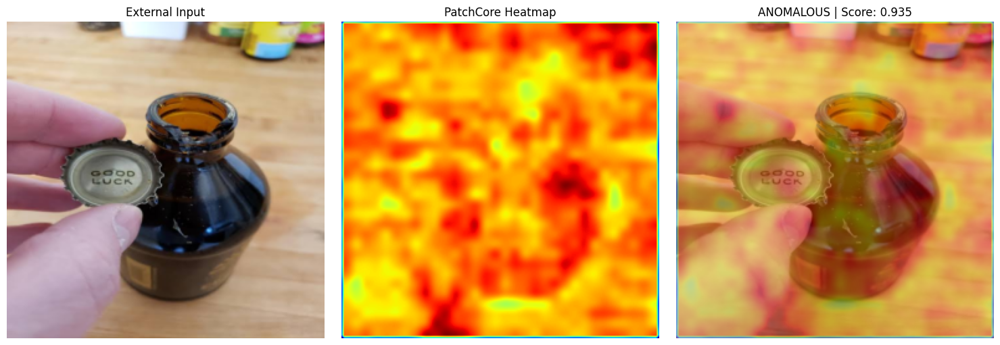


Result saved to: /content/drive/MyDrive/VisionInspect/results/heatmaps/external_bottle_inspection.png

STEP 25 COMPLETE ✅


In [179]:
# ============================================================
# STEP 25 — TEST VISIONINSPECT ON YOUR OWN IMAGE
# ============================================================

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import torch
import numpy as np

print("=" * 60)
print("VISIONINSPECT — EXTERNAL IMAGE INSPECTION")
print("=" * 60)

# ------------------------------------------------------------
# 1. UPLOAD IMAGE
# ------------------------------------------------------------

uploaded = files.upload()

uploaded_filename = list(uploaded.keys())[0]

print(
    "\nUploaded:",
    uploaded_filename
)

# ------------------------------------------------------------
# 2. LOAD ORIGINAL IMAGE
# ------------------------------------------------------------

external_image = Image.open(
    uploaded_filename
).convert("RGB")

print(
    "Original image size:",
    external_image.size
)

# ------------------------------------------------------------
# 3. PREPROCESS IMAGE
# ------------------------------------------------------------

external_tensor = image_transform(
    external_image
)

external_batch = (
    external_tensor
    .unsqueeze(0)
    .to(device)
)

print(
    "Model input shape:",
    external_batch.shape
)

# ------------------------------------------------------------
# 4. LOAD BOTTLE PATCHCORE MEMORY
# ------------------------------------------------------------

bottle_checkpoint = torch.load(
    MODEL_ROOT
    / "patchcore_bottle_memory.pt",
    map_location="cpu"
)

external_memory_bank = (
    bottle_checkpoint[
        "memory_bank"
    ]
)

# Restore projection used by Bottle model
projection_matrix = (
    bottle_checkpoint[
        "projection_matrix"
    ]
    .to(device)
)

print(
    "Bottle memory bank:",
    external_memory_bank.shape
)

# ------------------------------------------------------------
# 5. RUN PATCHCORE
# ------------------------------------------------------------

with torch.no_grad():

    external_score, external_map = (
        patchcore_score_with_memory(
            external_batch,
            external_memory_bank
        )
    )

score_value = float(
    external_score.item()
)

# Bottle threshold from our experiment
threshold_value = float(
    PATCHCORE_THRESHOLD
)

prediction = (
    "ANOMALOUS"
    if score_value >= threshold_value
    else "NORMAL"
)

print("\n" + "=" * 60)

print(
    "Prediction:",
    prediction
)

print(
    f"Anomaly Score: "
    f"{score_value:.4f}"
)

print(
    f"Bottle Threshold: "
    f"{threshold_value:.4f}"
)

print("=" * 60)

# ------------------------------------------------------------
# 6. UPSCALE HEATMAP
# ------------------------------------------------------------

external_map = upscale_patchcore_map(
    external_map,
    output_size=IMAGE_SIZE
)

# Normalize ONLY for visualization
visual_map = external_map.clone()

visual_map = (
    visual_map - visual_map.min()
) / (
    visual_map.max()
    - visual_map.min()
    + 1e-8
)

heatmap = (
    visual_map[0, 0]
    .cpu()
    .numpy()
)

# ------------------------------------------------------------
# 7. PREPARE IMAGE FOR DISPLAY
# ------------------------------------------------------------

display_image = denormalize_image(
    external_tensor
)

display_image = (
    display_image
    .permute(1, 2, 0)
    .numpy()
)

# ------------------------------------------------------------
# 8. VISUALIZE RESULT
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

axes[0].imshow(
    display_image
)

axes[0].set_title(
    "External Input"
)

axes[0].axis("off")


axes[1].imshow(
    heatmap,
    cmap="jet"
)

axes[1].set_title(
    "PatchCore Heatmap"
)

axes[1].axis("off")


axes[2].imshow(
    display_image
)

axes[2].imshow(
    heatmap,
    cmap="jet",
    alpha=0.45
)

axes[2].set_title(
    f"{prediction} | Score: {score_value:.3f}"
)

axes[2].axis("off")


plt.tight_layout()

# ------------------------------------------------------------
# 9. SAVE RESULT
# ------------------------------------------------------------

external_result_path = (
    RESULT_HEATMAP_ROOT
    / "external_bottle_inspection.png"
)

fig.savefig(
    external_result_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "\nResult saved to:",
    external_result_path
)

print("\nSTEP 25 COMPLETE ✅")